Restaurant ratings EDA

1. Select businesses tagged Restaurants or Food.
2. Reserve a test set.
3. Clean attributes, hours, and locations.
4. Compare the two tags and their overlap.
5. Check missing data and geographic coverage.
6. Explore all attributes, category tags, and detailed hours.
7. Save the data and full predictor summaries.

Focus on features an owner could specify before opening; Yelp does not verify their opening-day values.

Expand a result to see its explanations, charts, and full tables. Code is collapsed by default.

In [1]:
# Presentation only: analyses below are unchanged and remain executable.
from IPython.utils.capture import capture_output as _capture_output
from IPython.display import display as _compact_display, HTML as _CompactHTML
from html import escape as _escape_html
import re as _compact_re

def _compact_result(captured, title, notes, table_labels, chart_labels):
    findings, content = [], []
    table_count = chart_count = 0
    for output in captured.outputs:
        data = output.data
        if 'text/markdown' in data:
            text = data['text/markdown']
            findings.append(text)
        elif 'text/html' in data:
            html = data['text/html']
            if '<details' in html:
                # Keep existing full-table captions; constrain expanded table height.
                html = html.replace('</summary>', '</summary><div style="max-height:420px;overflow:auto;">', 1)
                html = html.replace('</details>', '</div></details>', 1)
                content.append(html)
            else:
                label = table_labels[table_count] if table_count < len(table_labels) else f'Table {table_count + 1}'
                content.append('<details><summary>' + _escape_html(label) + '</summary>' +
                    '<div style="max-height:420px;overflow:auto;">' + html + '</div></details>')
            table_count += 1
        elif 'image/png' in data:
            label = chart_labels[chart_count] if chart_count < len(chart_labels) else f'Chart {chart_count + 1}'
            png = data['image/png']
            if isinstance(png, list):
                png = ''.join(png)
            content.append('<details><summary>' + _escape_html(label) + '</summary>' +
                '<img alt="' + _escape_html(label, quote=True) + '" src="data:image/png;base64,' + png +
                '" style="display:block;max-width:100%;height:auto;" /></details>')
            chart_count += 1
        elif 'text/plain' in data:
            content.append('<pre style="white-space:pre-wrap;">' + _escape_html(data['text/plain']) + '</pre>')
    preview = ''
    if findings:
        first = _compact_re.sub(r'^Takeaway(?: to adapt)?:\s*', '', findings[0])
        preview = _compact_re.split(r'(?<=[.!?])\s+', first, maxsplit=1)[0]
    count_labels = []
    if chart_count:
        count_labels.append(f'{chart_count} chart' + ('s' if chart_count != 1 else ''))
    if table_count:
        count_labels.append(f'{table_count} table' + ('s' if table_count != 1 else ''))
    label = title + (' · ' + ', '.join(count_labels) if count_labels else '')
    body = ''.join('<p style="white-space:pre-wrap;">' + _escape_html(text) + '</p>' for text in findings)
    if notes:
        body += '<details><summary>Explanation</summary><div style="white-space:pre-wrap;">' + _escape_html(notes) + '</div></details>'
    body += ''.join(content)
    logs = captured.stdout + captured.stderr
    if logs:
        body += '<details><summary>Execution notes</summary><pre style="white-space:pre-wrap;max-height:300px;overflow:auto;">' + _escape_html(logs) + '</pre></details>'
    html = '<div style="font:inherit;color:inherit;margin:6px 0;">'
    if preview:
        html += '<p style="margin:0 0 6px;">' + _escape_html(preview) + '</p>'
    html += '<details><summary>' + _escape_html(label) + '</summary>' + body + '</details></div>'
    _compact_display(_CompactHTML(html))

with _capture_output() as _captured_section:
    from pathlib import Path
    import ast
    import hashlib
    import json
    import platform
    import sys
    import numpy as np
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt
    from IPython.display import display, Markdown

    get_ipython().run_line_magic('matplotlib', 'inline')

    # Locate the project from either its root or the notebooks directory.
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / 'data/source_manifest.json').exists())
    RAW = ROOT / 'data/01_raw'
    OUT = ROOT / 'reports/eda'
    PROCESSED = ROOT / 'data/02_processed'
    OUT.mkdir(parents=True, exist_ok=True)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    SEED = 6021
    plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                         'axes.spines.right': False, 'font.size': 10})
    BLUE, ORANGE = '#276A86', '#B56A3D'

    def finish(fig, filename):
        fig.text(0.01, 0.005, 'Source: local Yelp Open Dataset; development restaurants only; snapshot downloaded 2026-10-21.',
                 fontsize=8, color='dimgray')
        fig.tight_layout(rect=[0, 0.08, 1, 1])
        fig.savefig(OUT / filename, dpi=160, bbox_inches='tight')
        plt.show()

    def takeaway(text):
        display(Markdown('Takeaway: ' + text))

    business = pd.read_json(RAW / 'yelp_academic_dataset_business.json', lines=True,
                            dtype={'business_id': str, 'postal_code': str})
    category_lists = business['categories'].fillna('').map(
        lambda value: [x.strip() for x in value.split(',') if x.strip()])
    restaurant_mask = category_lists.map(lambda values: 'Restaurants' in values)
    food_mask = category_lists.map(lambda values: 'Food' in values)
    restaurants = business.loc[restaurant_mask].copy()
    restaurants['category_count'] = category_lists.loc[restaurant_mask].map(len)
    inventory = pd.DataFrame([
        ['Business rows', len(business)], ['Restaurant rows', len(restaurants)],
        ['Businesses missing categories', int(business.categories.isna().sum())],
    ], columns=['Measure', 'Count'])
    display(inventory)
    print('Kernel:', sys.executable)
    print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__)

_compact_result(_captured_section, 'Data overview', '1. Load the data\n\nKeep all Restaurants-tagged businesses, including closed ones. Compare Food separately and count shared businesses once. Check IDs and numeric ranges.', ['Business and restaurant counts'], [])

,Measure,Count
0,Business rows,150346
1,Restaurant rows,52268
2,Businesses missing categories,103


In [2]:
with _capture_output() as _captured_section:
    # Structural checks use all source rows. Target-driven exploration starts AFTER the split.
    quality = pd.Series({
        'business IDs missing': int(business.business_id.isna().sum()),
        'duplicate business IDs': int(business.business_id.duplicated().sum()),
        'restaurant ratings missing or outside 1–5': int((~restaurants.stars.between(1, 5)).sum()),
        'restaurant ratings not on half-star increments': int((restaurants.stars.mul(2) % 1 != 0).sum()),
        'restaurant review counts invalid': int(((restaurants.review_count < 0) | restaurants.review_count.isna()).sum()),
        'restaurant latitude invalid': int((~restaurants.latitude.between(-90, 90)).sum()),
        'restaurant longitude invalid': int((~restaurants.longitude.between(-180, 180)).sum()),
        'restaurant open status invalid': int((~restaurants.is_open.isin([0, 1])).sum()),
    }, name='Rows flagged')
    display(quality.to_frame())
    assert quality.sum() == 0, 'Inspect structural problems before proceeding; do not silently drop them.'
    takeaway(f'The source contains {len(business):,} businesses, of which {len(restaurants):,} carry the Restaurants category. '
             'Our unit of analysis is one restaurant, so each restaurant receives one row and equal weight in this EDA.')

_compact_result(_captured_section, 'Data checks', '', ['Missing IDs, duplicates, and invalid values'], [])

,Rows flagged
business IDs missing,0
duplicate business IDs,0
restaurant ratings missing or outside 1–5,0
restaurant ratings not on half-star increments,0
restaurant review counts invalid,0
restaurant latitude invalid,0
restaurant longitude invalid,0
restaurant open status invalid,0


In [3]:
with _capture_output() as _captured_section:
    def split_score(business_id):
        digest = hashlib.sha256(f'{SEED}:{business_id}'.encode()).digest()
        return int.from_bytes(digest[:8], 'big') / 2**64

    restaurants['split'] = restaurants.business_id.map(
        lambda key: 'holdout' if split_score(key) < 0.20 else 'development')
    development_ids = set(restaurants.loc[restaurants.split.eq('development'), 'business_id'])
    holdout_ids = set(restaurants.loc[restaurants.split.eq('holdout'), 'business_id'])
    assert development_ids.isdisjoint(holdout_ids)
    assert len(development_ids) + len(holdout_ids) == len(restaurants)
    print(f'Development: {len(development_ids):,} restaurants; holdout: {len(holdout_ids):,} restaurants.')

_compact_result(_captured_section, 'Development and holdout split', '2. Split the data\n\nReserve about 20% using business IDs. Explore ratings using only the development set.', [], [])

In [4]:
with _capture_output() as _captured_section:
    def decode_attribute(value):
        if value is None or (isinstance(value, str) and value.strip() in ['', 'None', 'null']):
            return None
        if isinstance(value, str):
            try:
                return ast.literal_eval(value)
            except (ValueError, SyntaxError):
                return value.strip()
        return value

    def attribute_value(attributes, key):
        return decode_attribute(attributes.get(key)) if isinstance(attributes, dict) else None

    # Clean the union once so all comparisons use identical preparation.
    comparison_businesses = business.loc[restaurant_mask | food_mask].copy()
    comparison_businesses['category_count'] = category_lists.loc[comparison_businesses.index].map(len)
    comparison_businesses['split'] = comparison_businesses.business_id.map(
        lambda key: 'holdout' if split_score(key) < 0.20 else 'development')
    assert comparison_businesses.business_id.is_unique
    assert comparison_businesses.stars.between(1, 5).all()
    assert comparison_businesses.stars.mul(2).mod(1).eq(0).all()
    assert comparison_businesses.review_count.ge(0).all()
    assert comparison_businesses.latitude.between(-90, 90).all()
    assert comparison_businesses.longitude.between(-180, 180).all()
    assert comparison_businesses.is_open.isin([0, 1]).all()
    feature_frame = comparison_businesses.drop(columns=['attributes', 'hours', 'address', 'name', 'categories']).copy()
    attribute_keys = {
        'price_range': 'RestaurantsPriceRange2', 'takeout': 'RestaurantsTakeOut',
        'delivery': 'RestaurantsDelivery', 'outdoor_seating': 'OutdoorSeating',
        'reservations': 'RestaurantsReservations', 'alcohol': 'Alcohol',
        'wifi': 'WiFi', 'noise_level': 'NoiseLevel',
    }
    binary_attributes = ['takeout', 'delivery', 'outdoor_seating', 'reservations']
    for new_name, raw_key in attribute_keys.items():
        values = comparison_businesses.attributes.map(lambda attrs: attribute_value(attrs, raw_key))
        if new_name in binary_attributes:
            feature_frame[new_name] = values.map(
                lambda value: 'Yes' if value is True else ('No' if value is False else np.nan))
        elif new_name == 'price_range':
            # Missing numeric entries may make pandas represent integers as floats.
            price_numeric = pd.to_numeric(values, errors='coerce')
            feature_frame[new_name] = price_numeric.map(
                lambda value: str(int(value)) if value in [1, 2, 3, 4] else np.nan)
        else:
            feature_frame[new_name] = values.map(lambda value: str(value) if value is not None else np.nan)

    def time_minutes(value):
        hour, minute = map(int, value.split(':'))
        if not (0 <= hour <= 24 and 0 <= minute < 60 and (hour != 24 or minute == 0)):
            raise ValueError('Invalid clock time')
        return hour * 60 + minute

    def summarize_hours(hours):
        if not isinstance(hours, dict) or not hours:
            return pd.Series([np.nan, np.nan, False, False])
        total = 0.0
        ambiguous = malformed = False
        for interval in hours.values():
            try:
                start, end = interval.split('-')
                duration = (time_minutes(end) - time_minutes(start)) % 1440
                if duration == 0:
                    ambiguous = True
                total += duration / 60
            except (AttributeError, ValueError, TypeError):
                malformed = True
        return pd.Series([len(hours), np.nan if ambiguous or malformed else total, ambiguous, malformed])

    feature_frame[['listed_days', 'weekly_listed_hours', 'hours_ambiguous', 'hours_malformed']] = (
        comparison_businesses.hours.apply(summarize_hours))
    # Normalize one explicit city-name variation, preserving the source city column.
    city_clean = feature_frame.city.str.strip().copy()
    st_louis = feature_frame.state.eq('MO') & city_clean.isin(['Saint Louis', 'St Louis', 'St. Louis'])
    city_clean.loc[st_louis] = 'St. Louis'
    city_label_changes = int(city_clean.ne(feature_frame.city).sum())
    feature_frame['city_state'] = city_clean + ', ' + feature_frame.state.str.strip()
    feature_frame['log1p_review_count'] = np.log1p(feature_frame.review_count)
    # Keep the existing restaurant exports/schema stable; add tags to the comparison data.
    combined_features = feature_frame.copy()
    combined_features['is_restaurant_tag'] = restaurant_mask.loc[combined_features.index]
    combined_features['is_food_tag'] = food_mask.loc[combined_features.index]
    combined_features['category_group'] = np.select(
        [combined_features.is_restaurant_tag & combined_features.is_food_tag,
         combined_features.is_restaurant_tag], ['Both tags', 'Restaurants only'], default='Food only')
    assert combined_features.weekly_listed_hours.dropna().between(0, 168).all()
    feature_frame = feature_frame.loc[restaurant_mask.loc[feature_frame.index]].copy()
    city_label_changes = int(city_clean.loc[feature_frame.index].ne(feature_frame.city).sum())
    dev = feature_frame.loc[feature_frame.split.eq('development')].copy()
    numeric_features = ['latitude', 'longitude', 'category_count', 'listed_days', 'weekly_listed_hours']
    categorical_features = ['state', 'city_state', *attribute_keys.keys()]
    assert len(numeric_features) >= 4 and len(categorical_features) >= 4
    assert dev[list(attribute_keys)].notna().any().all(), 'A decoded attribute unexpectedly became entirely missing'
    assert set(dev.price_range.dropna()) == {'1', '2', '3', '4'}
    assert dev.weekly_listed_hours.dropna().between(0, 168).all()
    dictionary = pd.DataFrame({
        'Variable': ['stars', *numeric_features, *categorical_features, 'review_count', 'is_open'],
        'Role': ['Target'] + ['Candidate numeric predictor'] * len(numeric_features)
                + ['Candidate categorical predictor'] * len(categorical_features)
                + ['Descriptive / availability-dependent', 'Descriptive / status at snapshot'],
    })
    display(dictionary)
    display(dev[numeric_features + ['stars', 'review_count']].describe().T.round(2))
    print(f'City-label normalization: {city_label_changes:,} rows changed; Saint Louis/St Louis/St. Louis in MO share one display label. Raw city preserved.')

_compact_result(_captured_section, 'Cleaned features', '3. Clean the data\n\nStandardize attributes and city names. Handle overnight hours and leave unclear schedules missing. Missing information does not mean No.', ['Feature dictionary', 'Numeric feature summaries'], [])

,Variable,Role
0,stars,Target
1,latitude,Candidate numeric predictor
2,longitude,Candidate numeric predictor
3,category_count,Candidate numeric predictor
4,listed_days,Candidate numeric predictor
5,weekly_listed_hours,Candidate numeric predictor
6,state,Candidate categorical predictor
7,city_state,Candidate categorical predictor
8,price_range,Candidate categorical predictor
9,takeout,Candidate categorical predictor



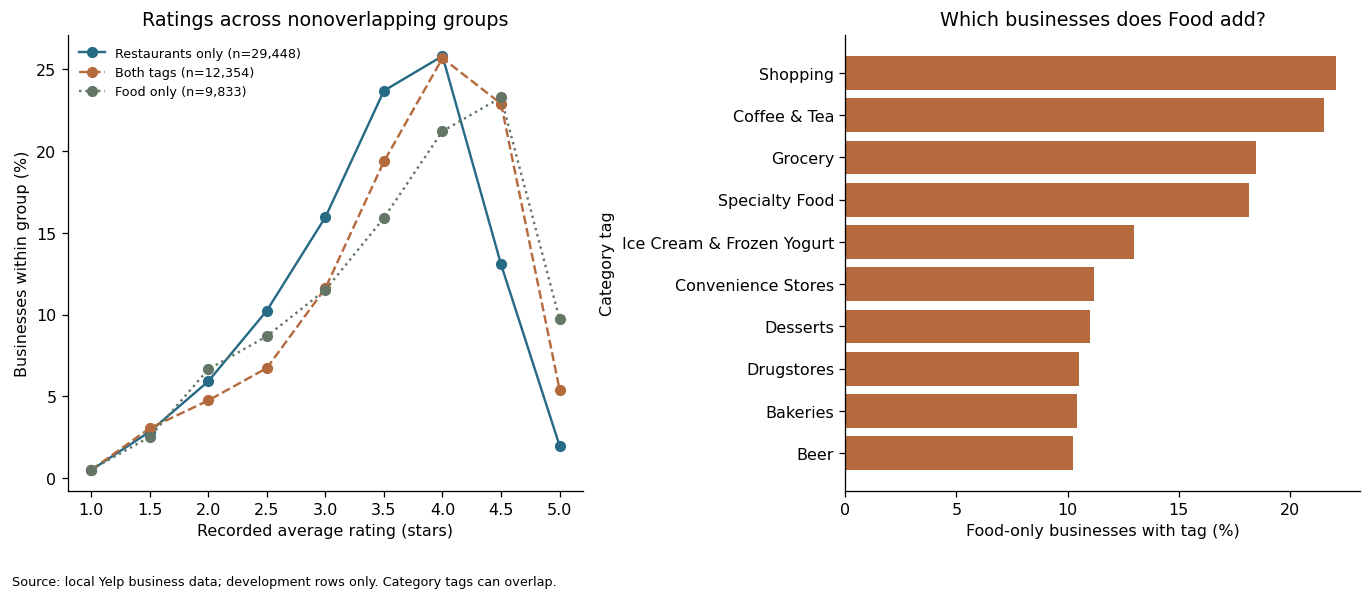
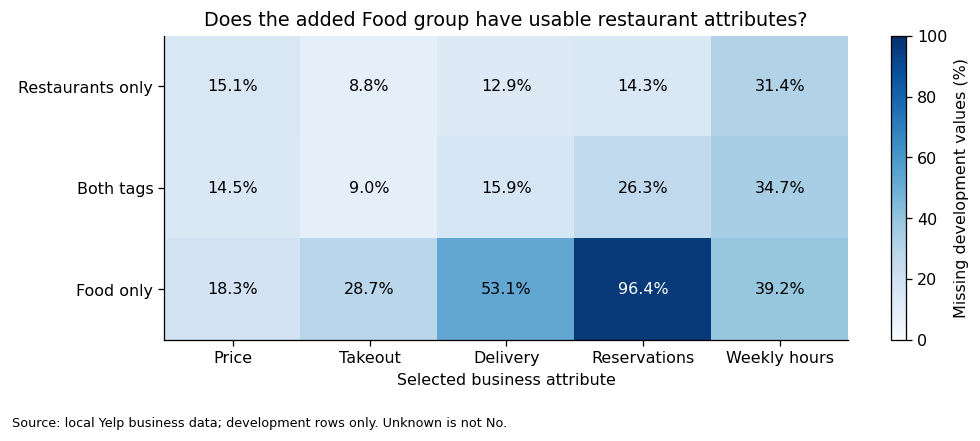

In [5]:
with _capture_output() as _captured_section:
    # AI-assisted scope comparison: exact tags, shared cleaning and stable ID splits.
    combined_dev = combined_features.loc[combined_features['split'].eq('development')].copy()
    cohort_masks = {
        'Restaurants (includes both)': combined_features.is_restaurant_tag,
        'Food (includes both)': combined_features.is_food_tag,
        'Both tags': combined_features.is_restaurant_tag & combined_features.is_food_tag,
        'Food only (added by union)': ~combined_features.is_restaurant_tag & combined_features.is_food_tag,
        'Restaurants or Food (union)': pd.Series(True, index=combined_features.index),
    }
    cohort_rows = []
    for label, mask in cohort_masks.items():
        all_rows = combined_features.loc[mask]
        development = all_rows.loc[all_rows['split'].eq('development')]
        cohort_rows.append({'group': label, 'all_businesses': len(all_rows),
            'development_businesses': len(development), 'mean_stars_dev': development.stars.mean(),
            'median_reviews_dev': development.review_count.median(),
            'under_20_reviews_pct_dev': development.review_count.lt(20).mean() * 100})
    cohort_comparison = pd.DataFrame(cohort_rows).set_index('group')
    assert len(combined_features) == int(restaurant_mask.sum() + food_mask.sum() - (restaurant_mask & food_mask).sum())
    assert combined_features.business_id.is_unique
    cohort_comparison.to_csv(OUT / 'restaurant_food_cohorts.csv')
    display(cohort_comparison.round(2))

    group_order = ['Restaurants only', 'Both tags', 'Food only']
    exclusive_summary = combined_dev.groupby('category_group').agg(
        development_businesses=('business_id', 'size'), mean_stars=('stars', 'mean'),
        median_reviews=('review_count', 'median')).reindex(group_order)
    missing_fields = ['price_range', 'takeout', 'delivery', 'reservations', 'weekly_listed_hours']
    missing_by_group = combined_dev.groupby('category_group')[missing_fields].agg(
        lambda values: values.isna().mean() * 100).reindex(group_order)
    exclusive_summary.to_csv(OUT / 'restaurant_food_exclusive_groups.csv')
    missing_by_group.to_csv(OUT / 'restaurant_food_missingness.csv')
    print('Mutually exclusive groups — development data:')
    display(exclusive_summary.round(2))
    print('Missing attributes by group (% of development businesses):')
    display(missing_by_group.round(1))

    # Food-only category labels identify the extra business mix without using holdout data.
    food_only_dev = combined_dev.loc[combined_dev.category_group.eq('Food only')]
    extra_categories = category_lists.loc[food_only_dev.index].map(lambda tags: list(dict.fromkeys(tags))).explode()
    extra_categories = extra_categories.loc[~extra_categories.isin(['Food', 'Restaurants'])]
    food_only_tags = extra_categories.value_counts().rename_axis('category').to_frame('development_businesses')
    food_only_tags['pct_food_only_development'] = food_only_tags.development_businesses / len(food_only_dev) * 100
    food_only_tags.to_csv(OUT / 'food_only_category_mix.csv')
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
    styles = [(BLUE, '-'), (ORANGE, '--'), ('#647766', ':')]
    for group, (color, style) in zip(group_order, styles):
        values = combined_dev.loc[combined_dev.category_group.eq(group), 'stars']
        percentages = values.value_counts(normalize=True).reindex(np.arange(1, 5.01, .5), fill_value=0) * 100
        axes[0].plot(percentages.index, percentages.values, marker='o', linestyle=style,
                     color=color, label=f'{group} (n={len(values):,})')
    axes[0].set(title='Ratings across nonoverlapping groups', xlabel='Recorded average rating (stars)',
                ylabel='Businesses within group (%)', xticks=np.arange(1, 5.01, .5))
    axes[0].legend(frameon=False, fontsize=8)
    shown = food_only_tags.head(10).iloc[::-1]
    axes[1].barh(shown.index, shown.pct_food_only_development, color=ORANGE)
    axes[1].set(title='Which businesses does Food add?', xlabel='Food-only businesses with tag (%)', ylabel='Category tag')
    fig.text(.01, .01, 'Source: local Yelp business data; development rows only. Category tags can overlap.', fontsize=8)
    fig.tight_layout(rect=[0, .06, 1, 1])
    fig.savefig(OUT / '09_restaurants_food_comparison.png', dpi=160, bbox_inches='tight')
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 3.8))
    heat = ax.imshow(missing_by_group.to_numpy(), vmin=0, vmax=100, cmap='Blues', aspect='auto')
    ax.set(xticks=range(len(missing_fields)), xticklabels=['Price', 'Takeout', 'Delivery', 'Reservations', 'Weekly hours'],
           yticks=range(3), yticklabels=group_order, xlabel='Selected business attribute',
           title='Does the added Food group have usable restaurant attributes?')
    for row in range(3):
        for col in range(len(missing_fields)):
            value = missing_by_group.iloc[row, col]
            ax.text(col, row, f'{value:.1f}%', ha='center', va='center', color='white' if value > 55 else 'black')
    fig.colorbar(heat, ax=ax, label='Missing development values (%)')
    fig.text(.01, .01, 'Source: local Yelp business data; development rows only. Unknown is not No.', fontsize=8)
    fig.tight_layout(rect=[0, .06, 1, 1])
    fig.savefig(OUT / '10_restaurants_food_missingness.png', dpi=160, bbox_inches='tight')
    plt.show()

    added = int((food_mask & ~restaurant_mask).sum())
    takeaway(f'Food adds {added:,} businesses beyond the {len(restaurants):,} Restaurants-tagged businesses, '
             f'giving {len(combined_features):,} unique businesses. Food-only development tags include '
             + ', '.join(food_only_tags.head(5).index) + '. Combining is valid for a broader food-business question, '
             'but changes the population and does not prove better restaurant prediction.')
    takeaway(f'Food-only delivery is missing for {missing_by_group.loc["Food only", "delivery"]:.1f}% of development rows, '
             f'versus {missing_by_group.loc["Restaurants only", "delivery"]:.1f}% for Restaurants only. '
             'Keep category-group indicators in a combined model and compare group-specific validation errors before adopting it; '
             'some restaurant attributes may not apply to the added businesses.')
    cohort_summary = {'all_restaurants': int(restaurant_mask.sum()), 'all_food': int(food_mask.sum()),
        'both': int((restaurant_mask & food_mask).sum()), 'food_only': added, 'union': len(combined_features),
        'development_comparison': cohort_comparison.reset_index().to_dict(orient='records'),
        'recommendation': 'Keep all Restaurants tags for the restaurant question. The union is usable for a broader food-business question, with deduplication and group-aware validation; predictive benefit is not tested here.'}
    (OUT / 'restaurant_food_summary.json').write_text(json.dumps(cohort_summary, indent=2, allow_nan=False))


_compact_result(_captured_section, 'Restaurants and Food', '3a. Compare Restaurants and Food\n\nCompare each tag, their overlap, and their combined group. Use development data for ratings and missingness. Adding Food broadens the study beyond restaurants.', ['Tag counts and development summaries', 'Mutually exclusive groups', 'Missingness by group'], ['Ratings and added Food categories', 'Missingness across Restaurants and Food'])

,missing_n,missing_pct,observed_unique
noise_level,13973,33.43,4
weekly_listed_hours,13535,32.38,444
wifi,11584,27.71,3
alcohol,9839,23.54,3
outdoor_seating,8281,19.81,2
reservations,7459,17.84,2
price_range,6235,14.92,4
listed_days,5808,13.89,7
delivery,5773,13.81,2
takeout,3713,8.88,2

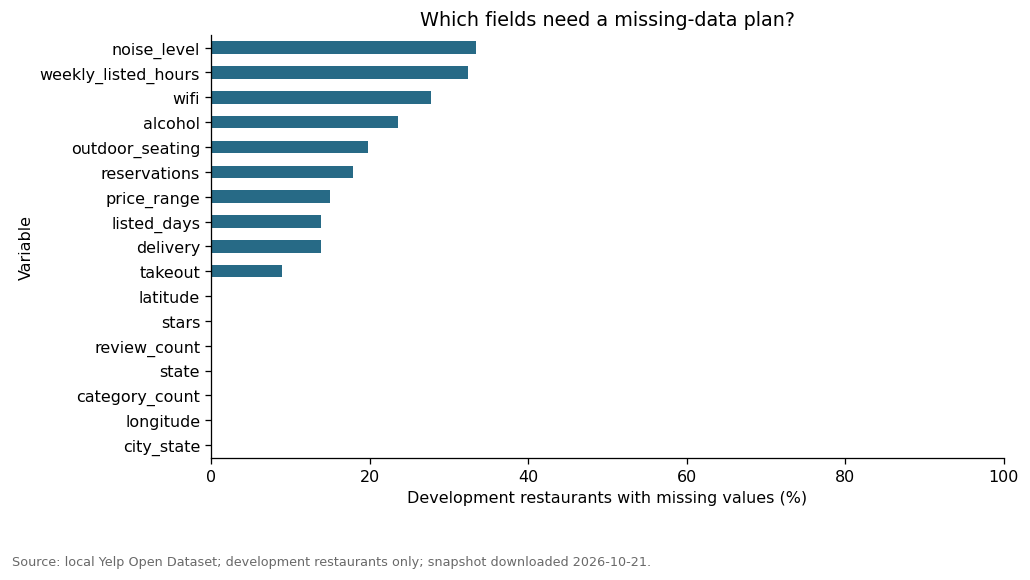

In [6]:
with _capture_output() as _captured_section:
    audit_columns = ['stars', 'review_count', *numeric_features, *categorical_features]
    missingness = pd.DataFrame({
        'missing_n': dev[audit_columns].isna().sum(),
        'missing_pct': dev[audit_columns].isna().mean() * 100,
        'observed_unique': dev[audit_columns].nunique(),
    }).sort_values('missing_pct', ascending=False)
    display(missingness.round(2))
    fig, ax = plt.subplots(figsize=(9, 5))
    missingness.missing_pct.sort_values().plot.barh(ax=ax, color=BLUE)
    ax.set(xlabel='Development restaurants with missing values (%)', ylabel='Variable',
           title='Which fields need a missing-data plan?', xlim=(0, 100))
    finish(fig, '01_missingness.png')
    display(pd.Series({
        'ambiguous hour schedules': int(dev.hours_ambiguous.sum()),
        'malformed hour schedules': int(dev.hours_malformed.sum()),
        'complete across all candidate predictors': int(dev[numeric_features + categorical_features].notna().all(axis=1).sum()),
    }, name='Development restaurants').to_frame())
    takeaway(f'The most incomplete selected field is {missingness.index[0]}, missing for {missingness.iloc[0].missing_pct:.1f}% of development restaurants. '
             'Unknown attributes must remain distinct from No. Missingness patterns alone do not establish why values are missing.')

_compact_result(_captured_section, 'Missing values', '4. Check missing values\n\nCount missing values and inspect unusual observations. Keep valid extremes, such as high review counts.', ['Missingness and unique values', 'Ambiguous schedules and complete rows'], ['Missingness by predictor'])

,restaurant_rows
PA,12641
FL,8731
TN,4352
MO,4247
IN,4150
LA,3640
NJ,3341
AZ,2671
NV,1673
ID,1302

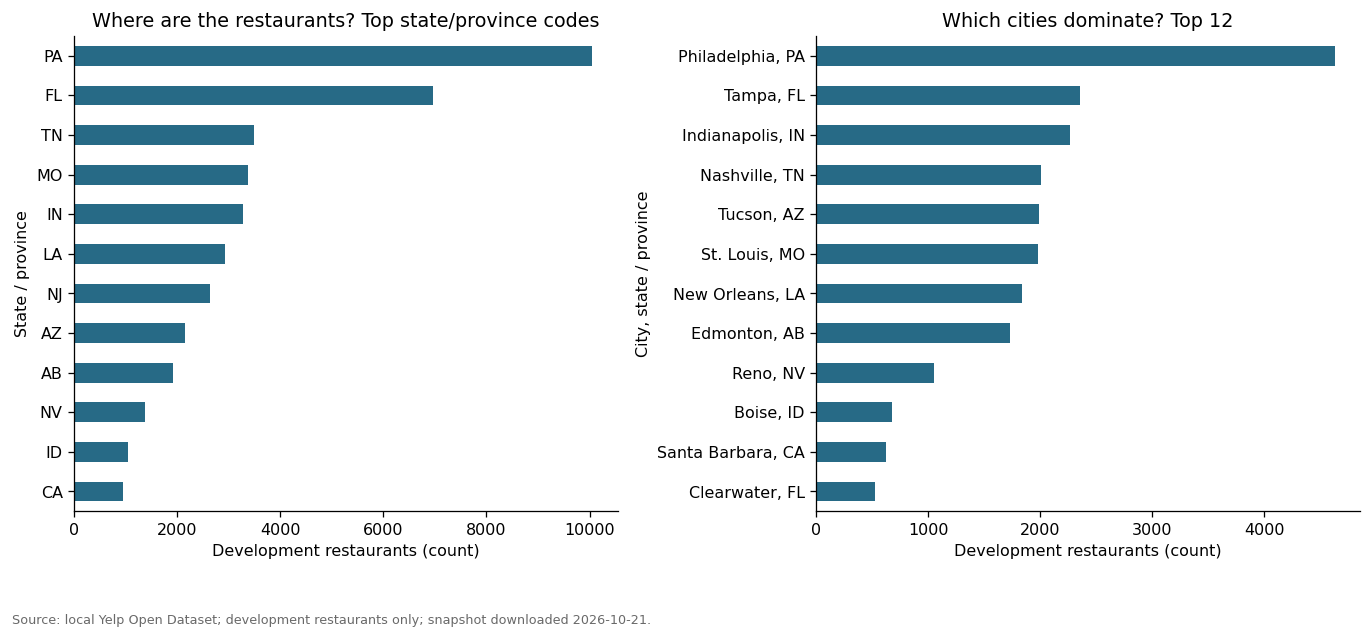

In [7]:
with _capture_output() as _captured_section:
    US_STATES = 'AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split()
    all_state_counts = restaurants.state.value_counts()
    us_coverage = all_state_counts.reindex(US_STATES, fill_value=0).rename('restaurant_rows').to_frame()
    zero_states = us_coverage.index[us_coverage.restaurant_rows.eq(0)].tolist()
    print(f'{len(zero_states)} of 50 US states have zero restaurant rows:')
    print(', '.join(zero_states))
    print('US states with at least one row:')
    display(us_coverage.query('restaurant_rows > 0').sort_values('restaurant_rows', ascending=False))
    print('Codes outside the 50 US states (inspect separately):')
    display(all_state_counts.loc[~all_state_counts.index.isin(US_STATES)].rename('restaurant_rows').to_frame())
    print('A code outside the US list may be a Canadian province (AB) or an anomalous code (XMS); do not infer a country from this test alone.')
    print('Regions with fewer than 30 restaurant rows, retained but unsuitable for regional comparisons:')
    display(all_state_counts[all_state_counts < 30].rename('restaurant_rows').to_frame())
    us_coverage.to_csv(OUT / 'us_state_coverage.csv', index_label='state')

    state_counts = dev.state.value_counts()
    city_counts = dev.city_state.value_counts()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    state_counts.head(12).sort_values().plot.barh(ax=axes[0], color=BLUE)
    city_counts.head(12).sort_values().plot.barh(ax=axes[1], color=BLUE)
    axes[0].set(title='Where are the restaurants? Top state/province codes', xlabel='Development restaurants (count)', ylabel='State / province')
    axes[1].set(title='Which cities dominate? Top 12', xlabel='Development restaurants (count)', ylabel='City, state / province')
    finish(fig, '02_geographic_coverage.png')
    takeaway(f'{len(zero_states)} of the 50 US states have no restaurant records in this release. '
             'State summaries describe the included locations, not representative statewide populations; a random holdout will not demonstrate generalization to unobserved regions.')

_compact_result(_captured_section, 'Geographic coverage', 'Keep incomplete rows where possible. Fill missing values using training data only.\n\n5. Check locations\n\nCount businesses by state, including states with no records. Coverage is limited; Alberta (AB) is in Canada.', ['US state counts', 'Codes outside the 50 US states', 'Sparse region counts'], ['Restaurant coverage by state'])

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
stars,41802.0,3.51,0.83,1.0,2.0,3.0,3.5,4.0,4.5,5.0,5.0
review_count,41802.0,87.80,193.11,5.0,6.0,13.0,33.0,89.0,333.0,759.0,7568.0

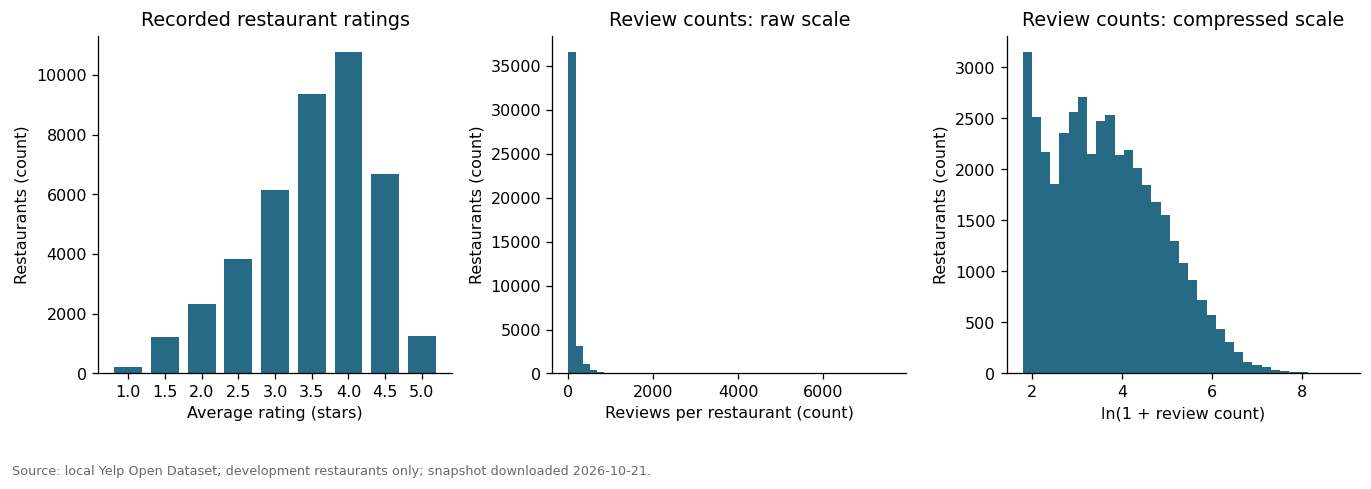

In [8]:
with _capture_output() as _captured_section:
    rating_counts = dev.stars.value_counts().reindex(np.arange(1, 5.01, 0.5), fill_value=0).sort_index()
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
    axes[0].bar(rating_counts.index, rating_counts.values, width=.38, color=BLUE)
    axes[0].set(title='Recorded restaurant ratings', xlabel='Average rating (stars)', ylabel='Restaurants (count)', xticks=np.arange(1, 5.1, .5))
    axes[1].hist(dev.review_count, bins=45, color=BLUE)
    axes[1].set(title='Review counts: raw scale', xlabel='Reviews per restaurant (count)', ylabel='Restaurants (count)')
    axes[2].hist(dev.log1p_review_count, bins=35, color=BLUE)
    axes[2].set(title='Review counts: compressed scale', xlabel='ln(1 + review count)', ylabel='Restaurants (count)')
    finish(fig, '03_ratings_and_review_counts.png')
    display(dev[['stars', 'review_count']].describe(percentiles=[.05, .25, .5, .75, .95, .99]).T.round(2))
    low_count_fraction = float(dev.review_count.lt(20).mean())
    takeaway(f'The development mean rating is {dev.stars.mean():.2f} stars and the median is {dev.stars.median():.1f}. '
             f'The median restaurant has {dev.review_count.median():.0f} reviews, and {low_count_fraction:.1%} have fewer than 20. '
             'These describe observed ratings; they do not measure future prediction accuracy.')

_compact_result(_captured_section, 'Ratings and review counts', '6. Explore ratings and reviews\n\nCompare business ratings and review counts. Ratings based on fewer reviews may be less stable.', ['Rating and review-count statistics'], ['Rating and review-count distributions'])

,size,mean,median,std
review_count_band,,,,
0–19,14614,3.340,3.5,0.951
20–49,10766,3.414,3.5,0.846
50–99,6972,3.618,3.5,0.712
100–249,6235,3.771,4.0,0.591
250+,3215,3.922,4.0,0.467

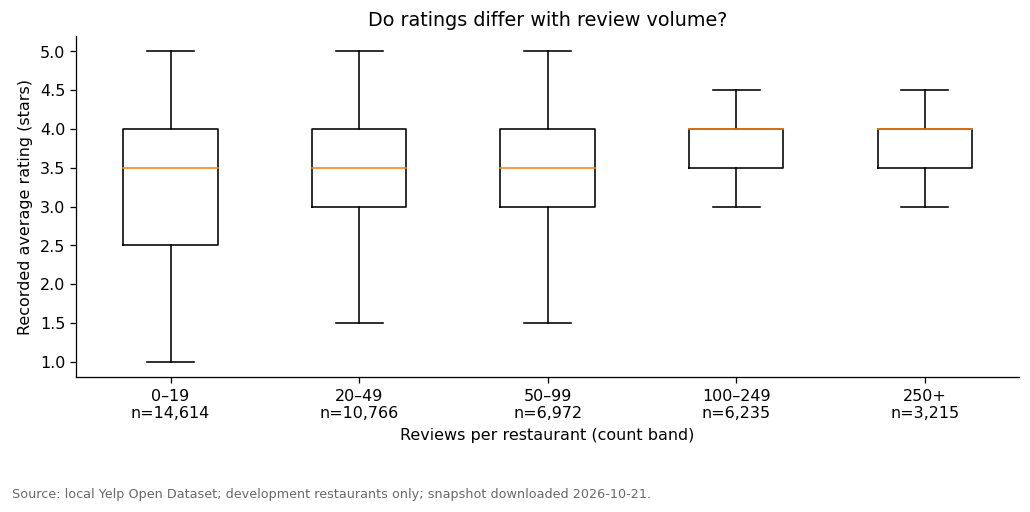

In [9]:
with _capture_output() as _captured_section:
    dev['review_count_band'] = pd.cut(dev.review_count, bins=[-1, 19, 49, 99, 249, np.inf],
                                     labels=['0–19', '20–49', '50–99', '100–249', '250+'])
    count_band_summary = dev.groupby('review_count_band', observed=True).stars.agg(['size', 'mean', 'median', 'std'])
    display(count_band_summary.round(3))
    fig, ax = plt.subplots(figsize=(9, 4.4))
    labels = list(count_band_summary.index.astype(str))
    groups = [dev.loc[dev.review_count_band.astype(str).eq(label), 'stars'].to_numpy() for label in labels]
    ax.boxplot(groups, labels=[f'{label}\nn={len(values):,}' for label, values in zip(labels, groups)], showfliers=False)
    ax.set(title='Do ratings differ with review volume?', xlabel='Reviews per restaurant (count band)', ylabel='Recorded average rating (stars)', ylim=(.8, 5.2))
    finish(fig, '04_rating_by_review_volume.png')
    takeaway('Review volume describes how much rating evidence a restaurant has, but it is accumulated after opening. '
             'Use it only if the eventual prediction scenario makes it available; it is excluded from the core attribute-only predictor list below. '
             'Differences between count bands cannot establish that more reviews cause better or more reliable ratings.')

_compact_result(_captured_section, 'Ratings by review volume', '', ['Ratings by review-count band'], ['Ratings across review-count bands'])

,size,mean,median,std
price_group,,,,
1,15593,3.298,3.5,0.932
2,18494,3.587,3.5,0.677
3,1331,3.683,4.0,0.617
4,149,3.644,4.0,0.800
Unknown,6235,3.802,4.0,0.887
,attribute,group,n,mean_stars
0,takeout,No,1820,3.320
1,takeout,Yes,36269,3.509
2,takeout,Unknown,3713,3.664

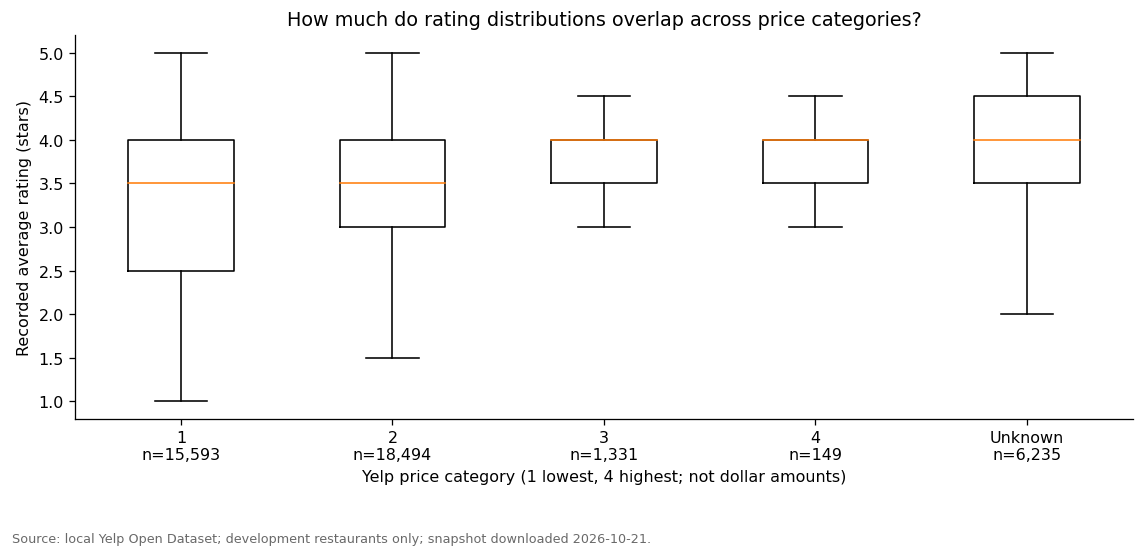
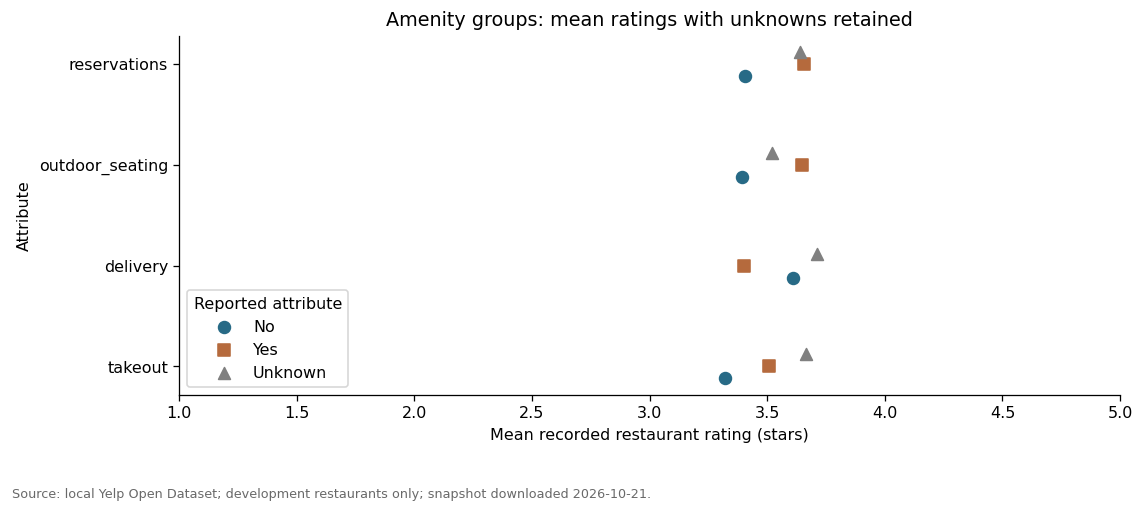

In [10]:
with _capture_output() as _captured_section:
    price_order = ['1', '2', '3', '4', 'Unknown']
    price_values = dev.price_range.fillna('Unknown')
    price_summary = dev.assign(price_group=price_values).groupby('price_group').stars.agg(['size', 'mean', 'median', 'std']).reindex(price_order)
    display(price_summary.round(3))
    fig, ax = plt.subplots(figsize=(10, 4.8))
    price_groups = [dev.loc[price_values.eq(label), 'stars'].to_numpy() for label in price_order]
    ax.boxplot(price_groups, labels=[f'{label}\nn={len(values):,}' for label, values in zip(price_order, price_groups)], showfliers=False)
    ax.set(title='How much do rating distributions overlap across price categories?',
           xlabel='Yelp price category (1 lowest, 4 highest; not dollar amounts)',
           ylabel='Recorded average rating (stars)', ylim=(.8, 5.2))
    finish(fig, '05_rating_by_price.png')

    amenity_rows = []
    for attribute in binary_attributes:
        table = dev.assign(group=dev[attribute].fillna('Unknown')).groupby('group').stars.agg(['size', 'mean', 'std'])
        for group in ['No', 'Yes', 'Unknown']:
            if group in table.index:
                amenity_rows.append({'attribute': attribute, 'group': group, 'n': int(table.loc[group, 'size']), 'mean_stars': float(table.loc[group, 'mean'])})
    amenity_summary = pd.DataFrame(amenity_rows)
    display(amenity_summary.round(3))
    fig, ax = plt.subplots(figsize=(10, 4.4))
    for offset, group, color, marker in [(-.12, 'No', BLUE, 'o'), (0, 'Yes', ORANGE, 's'), (.12, 'Unknown', 'gray', '^')]:
        values = amenity_summary.query('group == @group').set_index('attribute').reindex(binary_attributes)
        ax.scatter(values.mean_stars, np.arange(len(binary_attributes)) + offset, label=group, color=color, marker=marker, s=55)
    ax.set(yticks=np.arange(len(binary_attributes)), yticklabels=binary_attributes, xlim=(1, 5),
           title='Amenity groups: mean ratings with unknowns retained', xlabel='Mean recorded restaurant rating (stars)', ylabel='Attribute')
    ax.legend(title='Reported attribute', loc='lower left')
    finish(fig, '06_amenity_associations.png')
    takeaway(f'Price categories 1 and 2 average {price_summary.loc["1", "mean"]:.2f} and {price_summary.loc["2", "mean"]:.2f} stars, respectively, but their distributions overlap. '
             f'The Unknown price group averages {price_summary.loc["Unknown", "mean"]:.2f} stars, so discarding missing price rows can change the observed restaurant mix. '
             'These are descriptive associations, not evidence that increasing prices causes higher ratings.')

_compact_result(_captured_section, 'Price and amenities', '7. Compare business attributes\n\nCompare ratings by price and amenities, keeping Unknown separate. Differences do not establish cause and effect.', ['Ratings by price tier', 'Ratings by reported amenities'], ['Rating distributions by price', 'Takeout, delivery, seating, and reservations'])

,city,No,Yes,n_no,n_yes,Yes_minus_No
0,"Philadelphia, PA",3.602,3.509,1270,2756,-0.093
1,"Tampa, FL",3.633,3.518,746,1212,-0.115
2,"Indianapolis, IN",3.611,3.335,724,1252,-0.276
3,"Nashville, TN",3.651,3.427,710,956,-0.223
4,"Tucson, AZ",3.523,3.345,651,1041,-0.178
5,"St. Louis, MO",3.654,3.417,800,881,-0.237

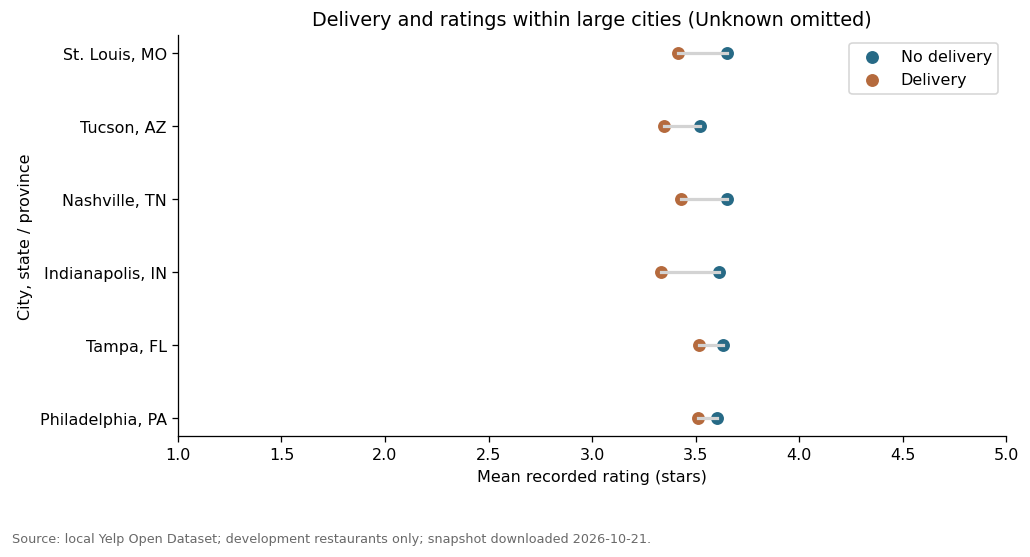

In [11]:
with _capture_output() as _captured_section:
    delivery_cities = city_counts.head(6).index
    delivery_by_city = (dev.loc[dev.city_state.isin(delivery_cities) & dev.delivery.isin(['Yes', 'No'])]
                       .groupby(['city_state', 'delivery']).stars.agg(['size', 'mean']))
    city_delivery_rows = []
    for city in delivery_cities:
        if city in delivery_by_city.index.get_level_values(0):
            groups = delivery_by_city.loc[city]
            if {'Yes', 'No'}.issubset(groups.index) and groups.loc[['Yes', 'No'], 'size'].min() >= 30:
                city_delivery_rows.append({'city': city, 'No': groups.loc['No', 'mean'], 'Yes': groups.loc['Yes', 'mean'],
                                           'n_no': int(groups.loc['No', 'size']), 'n_yes': int(groups.loc['Yes', 'size'])})
    delivery_city_summary = pd.DataFrame(city_delivery_rows)
    assert len(delivery_city_summary) > 0
    delivery_city_summary['Yes_minus_No'] = delivery_city_summary.Yes - delivery_city_summary.No
    display(delivery_city_summary.round(3))
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for index, row in delivery_city_summary.iterrows():
        ax.plot([row['No'], row['Yes']], [index, index], color='lightgray', linewidth=2)
    ax.scatter(delivery_city_summary['No'], np.arange(len(delivery_city_summary)), color=BLUE, label='No delivery', s=50)
    ax.scatter(delivery_city_summary['Yes'], np.arange(len(delivery_city_summary)), color=ORANGE, label='Delivery', s=50)
    ax.set(yticks=np.arange(len(delivery_city_summary)), yticklabels=delivery_city_summary.city, xlim=(1, 5),
           title='Delivery and ratings within large cities (Unknown omitted)', xlabel='Mean recorded rating (stars)', ylabel='City, state / province')
    ax.legend()
    finish(fig, '07_delivery_within_cities.png')
    takeaway('A pooled attribute difference can mix together restaurants from different markets. '
             'Within-city comparisons help reveal whether the relationship is consistent, but do not remove all confounding. '
             'These descriptive contrasts do not tell us what would happen if a restaurant changed its delivery policy.')

_compact_result(_captured_section, 'Delivery within cities', 'Compare delivery within cities\n\nCompare Yes and No in the six largest development cities, with at least 30 businesses per group. Leave Unknown out of this comparison.', ['Delivery comparison within cities'], ['Delivery and ratings within cities'])

,stars,review_count,latitude,longitude,category_count,listed_days,weekly_listed_hours
stars,1.000,0.203,-0.038,-0.003,0.105,-0.333,-0.431
review_count,0.203,1.000,-0.104,-0.044,0.215,0.014,-0.129
latitude,-0.038,-0.104,1.000,0.255,-0.061,0.009,0.007
longitude,-0.003,-0.044,0.255,1.000,-0.021,0.011,0.035
category_count,0.105,0.215,-0.061,-0.021,1.000,0.012,0.042
listed_days,-0.333,0.014,0.009,0.011,0.012,1.000,0.659
weekly_listed_hours,-0.431,-0.129,0.007,0.035,0.042,0.659,1.000
,stars,review_count,latitude,longitude,category_count,listed_days,weekly_listed_hours
stars,41802,41802,41802,41802,41802,35994,28267
review_count,41802,41802,41802,41802,41802,35994,28267

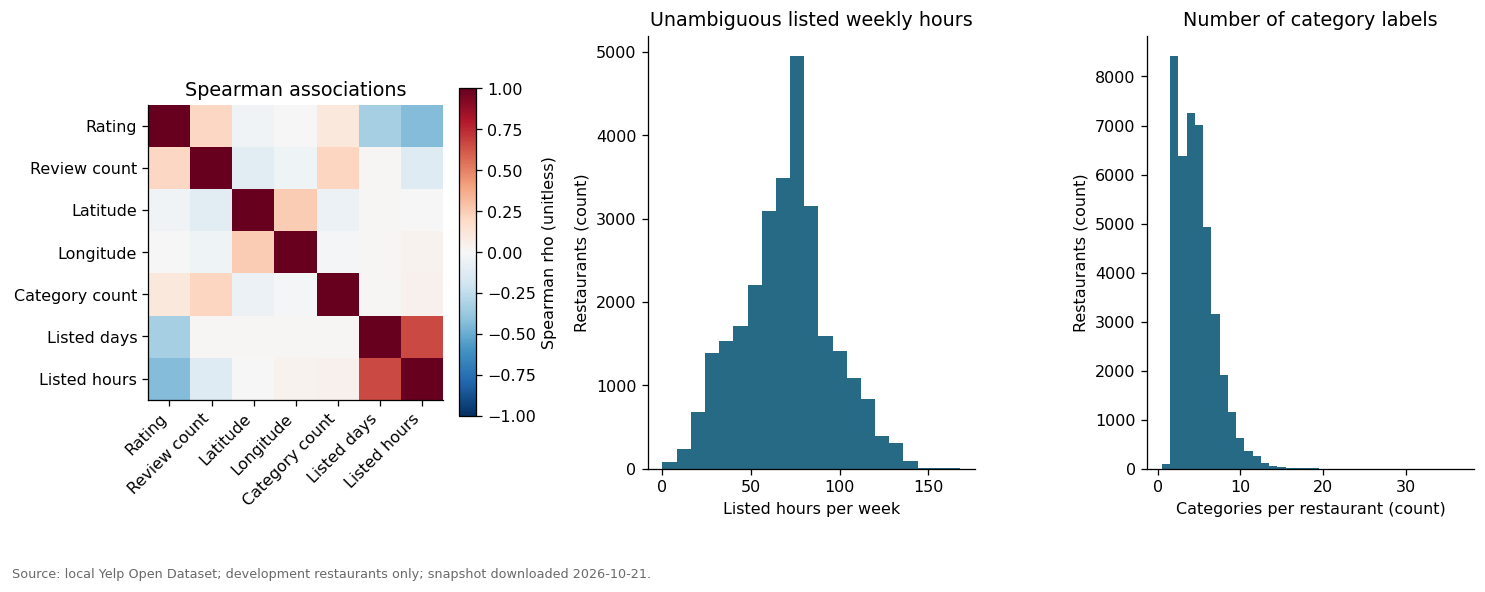

In [12]:
with _capture_output() as _captured_section:
    numeric_columns = ['stars', 'review_count', *numeric_features]
    correlations = dev[numeric_columns].corr(method='spearman')
    display(correlations.round(3))
    display(dev[numeric_columns].notna().astype(int).T.dot(dev[numeric_columns].notna().astype(int)))
    fig, axes = plt.subplots(1, 3, figsize=(13, 5.1))
    heat = axes[0].imshow(correlations.to_numpy(), vmin=-1, vmax=1, cmap='RdBu_r')
    short_labels = ['Rating', 'Review count', 'Latitude', 'Longitude', 'Category count', 'Listed days', 'Listed hours']
    axes[0].set(xticks=range(len(numeric_columns)), yticks=range(len(numeric_columns)),
                xticklabels=short_labels, yticklabels=short_labels, title='Spearman associations')
    plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
    fig.colorbar(heat, ax=axes[0], label='Spearman rho (unitless)', fraction=.05)
    axes[1].hist(dev.weekly_listed_hours.dropna(), bins=np.arange(0, 169, 8), color=BLUE)
    axes[1].set(title='Unambiguous listed weekly hours', xlabel='Listed hours per week', ylabel='Restaurants (count)')
    axes[2].hist(dev.category_count, bins=np.arange(.5, dev.category_count.max() + 1.5), color=BLUE)
    axes[2].set(title='Number of category labels', xlabel='Categories per restaurant (count)', ylabel='Restaurants (count)')
    finish(fig, '08_numeric_relationships.png')
    outlier_quantiles = dev[['review_count', 'category_count', 'weekly_listed_hours']].quantile([0, .01, .5, .99, 1]).T
    display(outlier_quantiles.round(2))
    takeaway('Numeric summaries help identify skew, unusual values, and possible redundant features. '
             'Large review counts are retained unless there is evidence of an error, and ambiguous schedules remain missing. '
             'Weak marginal correlations do not rule out interactions or nonlinear predictive relationships.')

_compact_result(_captured_section, 'Numeric relationships', '8. Compare numeric features\n\nInspect correlations, distributions, and unusual values. Correlation alone does not show predictive accuracy.', ['Spearman correlations', 'Pairwise nonmissing sample sizes', 'Numeric ranges and quantiles'], ['Correlations, listed hours, and category counts'])

In [13]:
with _capture_output() as _captured_section:
    # AI-assisted expansion: audit every attribute key, including sparse and nested fields.
    from IPython.display import HTML
    from html import escape
    AUDIT = OUT / 'predictor_audit'
    AUDIT.mkdir(parents=True, exist_ok=True)
    raw_development = comparison_businesses.loc[combined_dev.index].copy()
    assert raw_development['split'].eq('development').all()
    assert not set(raw_development.business_id) & holdout_ids

    def expandable_table(title, table, filename):
        # Full tables stay available without filling the notebook with hundreds of rows.
        table.to_csv(AUDIT / filename, index=False)
        display(HTML('<details><summary>' + escape(title) + '</summary>' +
                     table.to_html(index=False, max_rows=None, float_format=lambda x: f'{x:.3f}') + '</details>'))

    def normalized_level(value):
        value = decode_attribute(value)
        if value is None or isinstance(value, (dict, list, tuple)) or (isinstance(value, (float, np.floating)) and np.isnan(value)):
            return np.nan
        if isinstance(value, (bool, np.bool_)):
            return 'Yes' if value else 'No'
        if isinstance(value, (int, float, np.number)):
            return str(int(value)) if np.isfinite(value) and float(value).is_integer() else str(value)
        return str(value).strip()

    # Discover source schema without looking at holdout rating distributions.
    all_keys = sorted({key for attrs in comparison_businesses.attributes
                       if isinstance(attrs, dict) for key in attrs})
    decoded = comparison_businesses.attributes.map(
        lambda attrs: {k: decode_attribute(v) for k, v in attrs.items()} if isinstance(attrs, dict) else {})
    attribute_frame = pd.DataFrame(index=raw_development.index)
    attribute_roots = {}
    source_rows = []
    for key in all_keys:
        source_values = decoded.map(lambda attrs: attrs.get(key))
        children = sorted({child for value in source_values if isinstance(value, dict) for child in value})
        development_values = source_values.loc[raw_development.index]
        if children:
            for child in children:
                name = f'{key}.{child}'
                attribute_frame[name] = development_values.map(
                    lambda value: normalized_level(value.get(child)) if isinstance(value, dict) else np.nan)
                attribute_roots[name] = key
            non_dictionary_values = development_values.map(lambda v: v is not None and not isinstance(v, dict)).sum()
        else:
            attribute_frame[key] = development_values.map(normalized_level)
            attribute_roots[key] = key
            non_dictionary_values = 0
        source_rows.append({'source_attribute': key, 'nested_options': len(children),
            'present_in_development': int(development_values.map(lambda v: isinstance(v, dict) or pd.notna(v)).sum()),
            'unexpected_non_dictionary_values': int(non_dictionary_values)})
    source_audit = pd.DataFrame(source_rows)
    assert set(attribute_roots.values()) == set(all_keys)
    assert attribute_frame.index.equals(raw_development.index)

    perception_roots = {'Ambience', 'NoiseLevel', 'GoodForKids', 'RestaurantsGoodForGroups',
                        'GoodForMeal', 'BestNights', 'GoodForDancing'}
    low_relevance_roots = {'AcceptsInsurance', 'HairSpecializesIn'}
    def planning_role(root):
        if root in low_relevance_roots:
            return 'Low relevance to restaurant planning'
        if root in perception_roots:
            return 'Perception or definition needs checking'
        return 'Owner-specifiable in principle'

    scope_masks = {
        'Restaurants': combined_dev.is_restaurant_tag,
        'Food': combined_dev.is_food_tag,
        'Food only': combined_dev.category_group.eq('Food only'),
        'Combined': pd.Series(True, index=combined_dev.index),
    }
    attribute_rows = []
    for feature in attribute_frame:
        values = attribute_frame[feature]
        record = {'feature': feature, 'planning_role': planning_role(attribute_roots[feature]),
            'known_n': int(values.notna().sum()), 'known_levels': int(values.nunique()),
            'sparse_under_100_known': bool(values.notna().sum() < 100)}
        for scope, mask in scope_masks.items():
            record[f'missing_pct_{scope}'] = float(values.loc[mask].isna().mean() * 100)
        attribute_rows.append(record)
    attribute_inventory = pd.DataFrame(attribute_rows)
    expandable_table('All source attributes and nested-field checks', source_audit, 'source_attributes.csv')
    expandable_table('Every extracted attribute: coverage and planning suitability', attribute_inventory,
                     'attribute_inventory.csv')
    print(f'{len(all_keys)} source attributes → {len(attribute_frame.columns)} scalar or nested options audited.')
    print(f'{attribute_inventory.sparse_under_100_known.sum()} options have fewer than 100 known development values.')
    takeaway('Owner-specifiable means an owner could describe the feature; it does not prove that Yelp recorded its pre-opening value. '
             'Perception-based and sparse fields are explored here without endorsing them as model inputs.')

_compact_result(_captured_section, 'All attribute inventory', '8a. Check every available attribute\n\nExplore all attribute fields and nested options. Separate owner-specifiable features from customer perceptions and irrelevant fields. These are snapshot values, not verified opening-day records. All comparisons below use development data.', [], [])

source_attribute,nested_options,present_in_development,unexpected_non_dictionary_values
AcceptsInsurance,0,56,0
AgesAllowed,0,70,0
Alcohol,0,32634,0
Ambience,9,33143,0
BYOB,0,3449,0
BYOBCorkage,0,1134,0
BestNights,7,3688,0
BikeParking,0,35348,0
BusinessAcceptsBitcoin,0,6337,0
BusinessAcceptsCreditCards,0,44876,0


feature,scope,level,n,mean_stars,median_stars,sd_stars,group_pct
AcceptsInsurance,Restaurants,No,11,3.727,4.000,1.081,0.026
AcceptsInsurance,Restaurants,Unknown,41788,3.515,3.500,0.831,99.967
AcceptsInsurance,Restaurants,Yes,3,3.000,3.000,0.500,0.007
AcceptsInsurance,Food,No,31,4.274,4.500,0.705,0.140
AcceptsInsurance,Food,Unknown,22140,3.672,4.000,0.893,99.788
AcceptsInsurance,Food,Yes,16,3.406,4.000,1.307,0.072
AcceptsInsurance,Food only,No,27,4.241,4.500,0.739,0.275
AcceptsInsurance,Food only,Unknown,9791,3.676,4.000,0.932,99.573
AcceptsInsurance,Food only,Yes,15,3.433,4.000,1.348,0.153
AcceptsInsurance,Combined,No,38,4.092,4.500,0.869,0.074

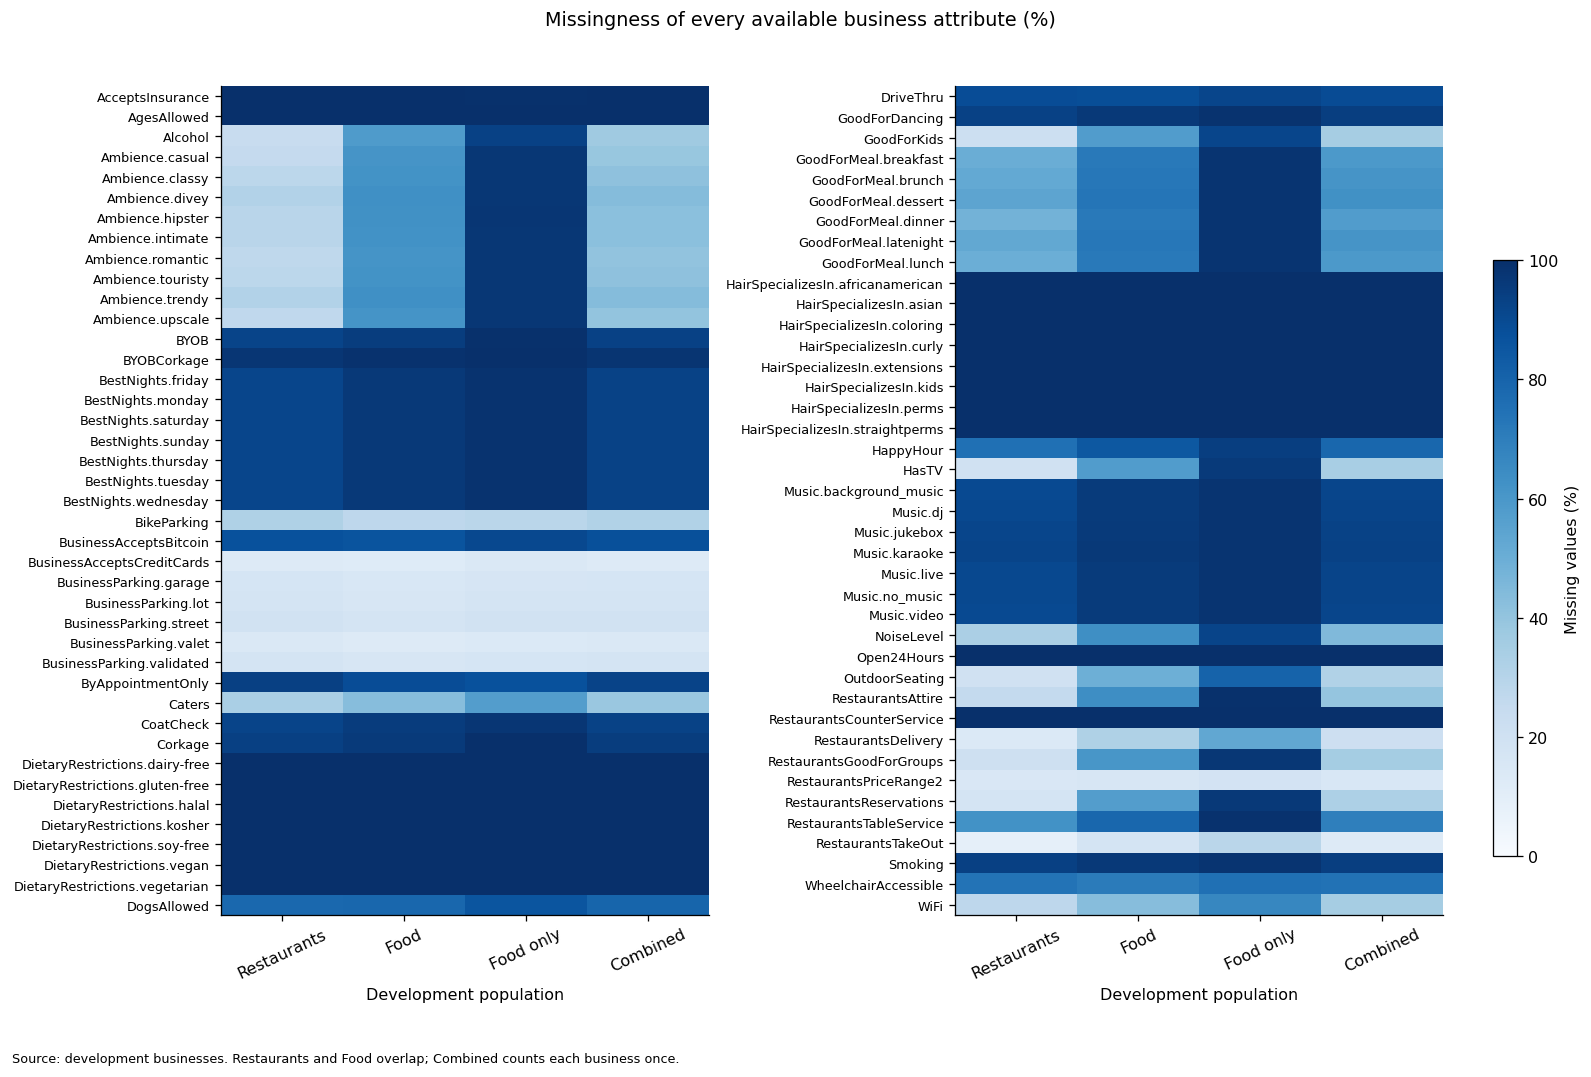
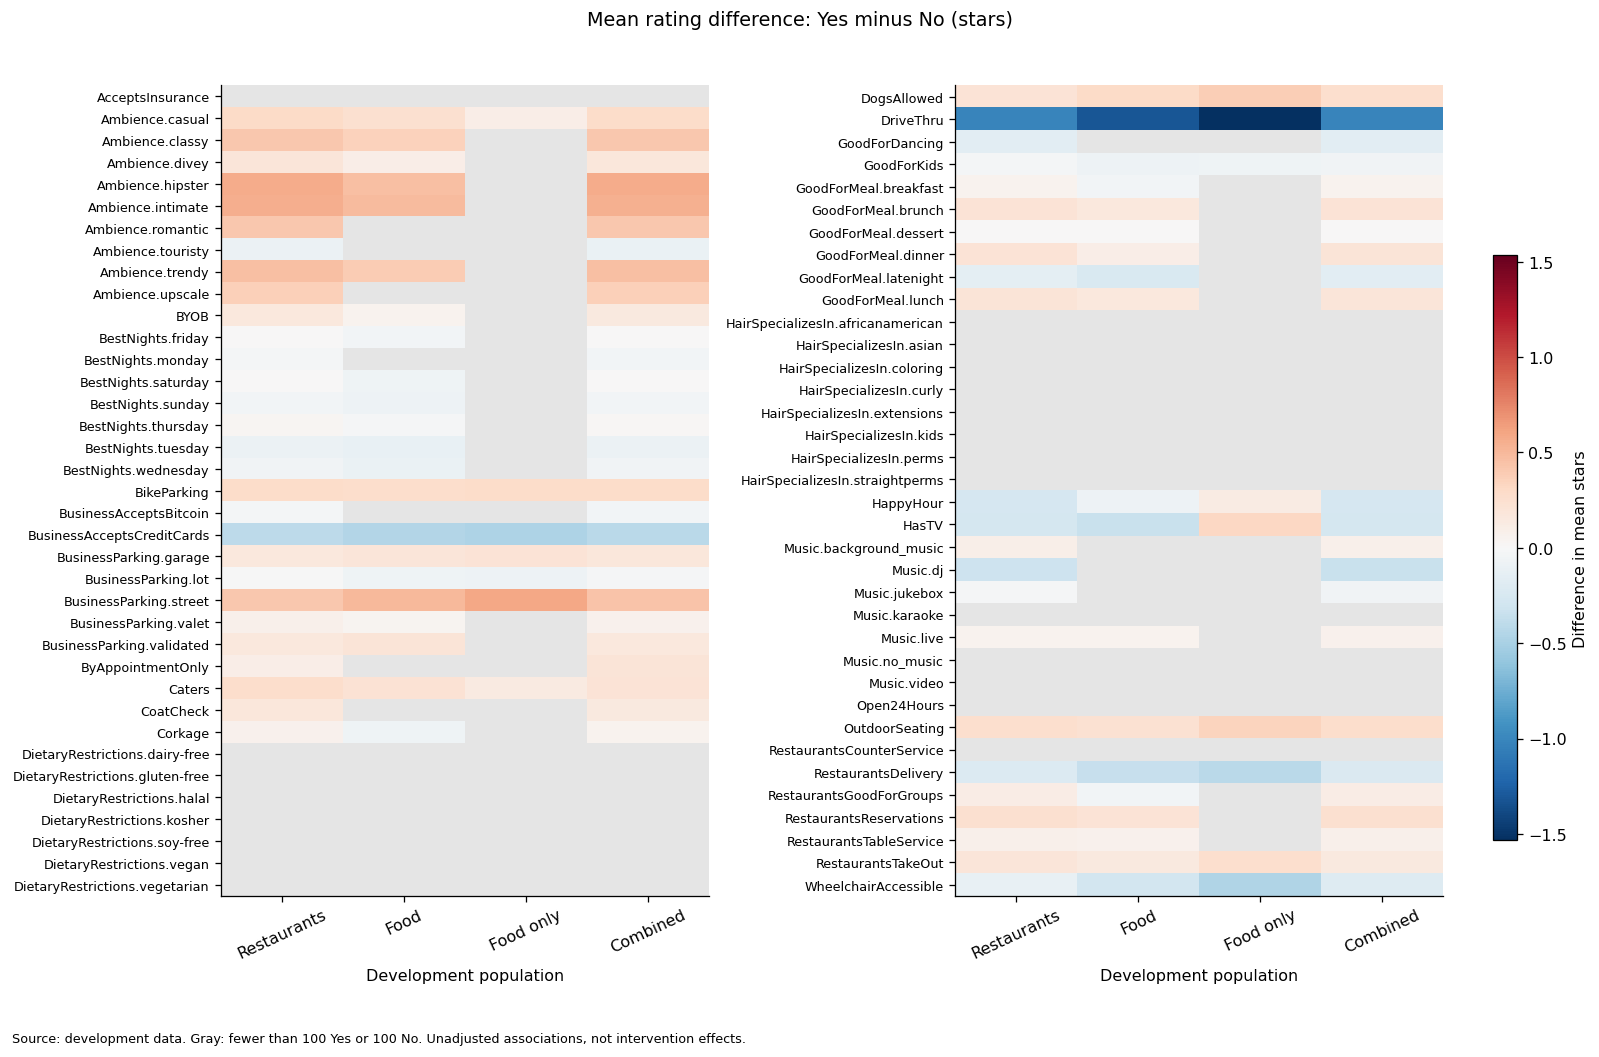

In [14]:
with _capture_output() as _captured_section:
    attribute_level_tables, attribute_rating_tables = [], []
    for feature in attribute_frame:
        values = attribute_frame[feature].fillna('Unknown')
        for scope, mask in scope_masks.items():
            table_data = pd.DataFrame({'level': values.loc[mask], 'stars': combined_dev.loc[mask, 'stars']})
            stats = table_data.groupby('level').stars.agg(n='size', mean_stars='mean',
                median_stars='median', sd_stars='std').reset_index()
            stats.insert(0, 'scope', scope)
            stats.insert(0, 'feature', feature)
            stats['group_pct'] = stats.n / len(table_data) * 100
            attribute_level_tables.append(stats)
            distribution = pd.crosstab(table_data.level, table_data.stars).reindex(
                columns=np.arange(1, 5.01, .5), fill_value=0)
            distribution = distribution.div(distribution.sum(axis=1), axis=0).mul(100)
            distribution.columns = [f'pct_{rating:g}_stars' for rating in distribution.columns]
            distribution = distribution.reset_index()
            distribution.insert(0, 'scope', scope)
            distribution.insert(0, 'feature', feature)
            attribute_rating_tables.append(distribution)
    attribute_levels = pd.concat(attribute_level_tables, ignore_index=True)
    attribute_rating_distributions = pd.concat(attribute_rating_tables, ignore_index=True)
    assert set(attribute_levels.feature) == set(attribute_frame.columns)
    for scope, mask in scope_masks.items():
        totals = attribute_levels.loc[attribute_levels.scope.eq(scope)].groupby('feature').n.sum()
        assert totals.eq(int(mask.sum())).all()
    expandable_table('Every attribute level: counts, prevalence, mean and median ratings',
                     attribute_levels, 'attribute_level_ratings.csv')
    expandable_table('Full half-star rating distributions for every attribute level',
                     attribute_rating_distributions, 'attribute_rating_distributions.csv')

    # Coverage for all extracted options, in two readable panels.
    coverage = attribute_inventory.set_index('feature')[[f'missing_pct_{s}' for s in scope_masks]]
    chunks = np.array_split(np.arange(len(coverage)), 2)
    fig, axes = plt.subplots(1, 2, figsize=(14, max(9, len(chunks[0]) * .23)))
    for ax, positions in zip(axes, chunks):
        block = coverage.iloc[positions]
        heat = ax.imshow(block, cmap='Blues', vmin=0, vmax=100, aspect='auto')
        ax.set(yticks=range(len(block)), yticklabels=block.index,
               xticks=range(4), xticklabels=list(scope_masks), xlabel='Development population')
        ax.tick_params(axis='y', labelsize=8)
        ax.tick_params(axis='x', labelrotation=25)
    fig.suptitle('Missingness of every available business attribute (%)', fontsize=12)
    fig.tight_layout(rect=[0, .05, .91, .96])
    cax = fig.add_axes([.93, .20, .015, .55])
    fig.colorbar(heat, cax=cax, label='Missing values (%)')
    fig.text(.01, .01, 'Source: development businesses. Restaurants and Food overlap; Combined counts each business once.', fontsize=8)
    fig.savefig(OUT / '11_all_attribute_coverage.png', dpi=140, bbox_inches='tight')
    plt.show()

    binary_features = [c for c in attribute_frame if
        set(attribute_frame[c].dropna().unique()).issubset({'Yes', 'No'})]
    binary_rows = []
    for feature in binary_features:
        for scope in scope_masks:
            rows = attribute_levels.loc[attribute_levels.feature.eq(feature) & attribute_levels.scope.eq(scope)].set_index('level')
            yes_n = int(rows.loc['Yes', 'n']) if 'Yes' in rows.index else 0
            no_n = int(rows.loc['No', 'n']) if 'No' in rows.index else 0
            difference = float(rows.loc['Yes', 'mean_stars'] - rows.loc['No', 'mean_stars']) if yes_n and no_n else np.nan
            binary_rows.append({'feature': feature, 'scope': scope, 'yes_n': yes_n, 'no_n': no_n,
                'mean_stars_yes_minus_no': difference, 'chart_supported': yes_n >= 100 and no_n >= 100})
    binary_comparison = pd.DataFrame(binary_rows)
    expandable_table('All binary comparisons, including sample sizes and sparse groups', binary_comparison,
                     'binary_attribute_comparisons.csv')
    chart_data = binary_comparison.assign(chart_difference=lambda d: d.mean_stars_yes_minus_no.where(d.chart_supported))
    chart_data = chart_data.pivot(index='feature', columns='scope', values='chart_difference').reindex(columns=list(scope_masks))
    chunks = np.array_split(np.arange(len(chart_data)), 2)
    color_limit = max(.1, float(np.nanmax(np.abs(chart_data.to_numpy()))))
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('#E5E5E5')
    fig, axes = plt.subplots(1, 2, figsize=(14, max(8, len(chunks[0]) * .25)))
    for ax, positions in zip(axes, chunks):
        block = chart_data.iloc[positions]
        heat = ax.imshow(np.ma.masked_invalid(block.to_numpy()), cmap=cmap,
                         vmin=-color_limit, vmax=color_limit, aspect='auto')
        ax.set(yticks=range(len(block)), yticklabels=block.index, xticks=range(4),
               xticklabels=list(scope_masks), xlabel='Development population')
        ax.tick_params(axis='y', labelsize=8)
        ax.tick_params(axis='x', labelrotation=25)
    fig.suptitle('Mean rating difference: Yes minus No (stars)', fontsize=12)
    fig.tight_layout(rect=[0, .05, .91, .96])
    cax = fig.add_axes([.93, .20, .015, .55])
    fig.colorbar(heat, cax=cax, label='Difference in mean stars')
    fig.text(.01, .01, 'Source: development data. Gray: fewer than 100 Yes or 100 No. Unadjusted associations, not intervention effects.', fontsize=8)
    fig.savefig(OUT / '12_all_binary_attribute_ratings.png', dpi=140, bbox_inches='tight')
    plt.show()

    takeaway('The full tables include every level, Unknown values, and its sample size. '
             'Large differences in tiny groups are not reliable evidence for choosing a business feature.')

_compact_result(_captured_section, 'All binary attribute comparisons', '8b. Compare all attribute values with ratings\n\nFor every option, show missingness, sample size, and rating distributions. The charts require at least 100 Yes and 100 No records per group. Small groups remain in the full tables; differences are descriptive, not causal.', [], ['Coverage of all 81 attribute options', 'Ratings for all binary options'])


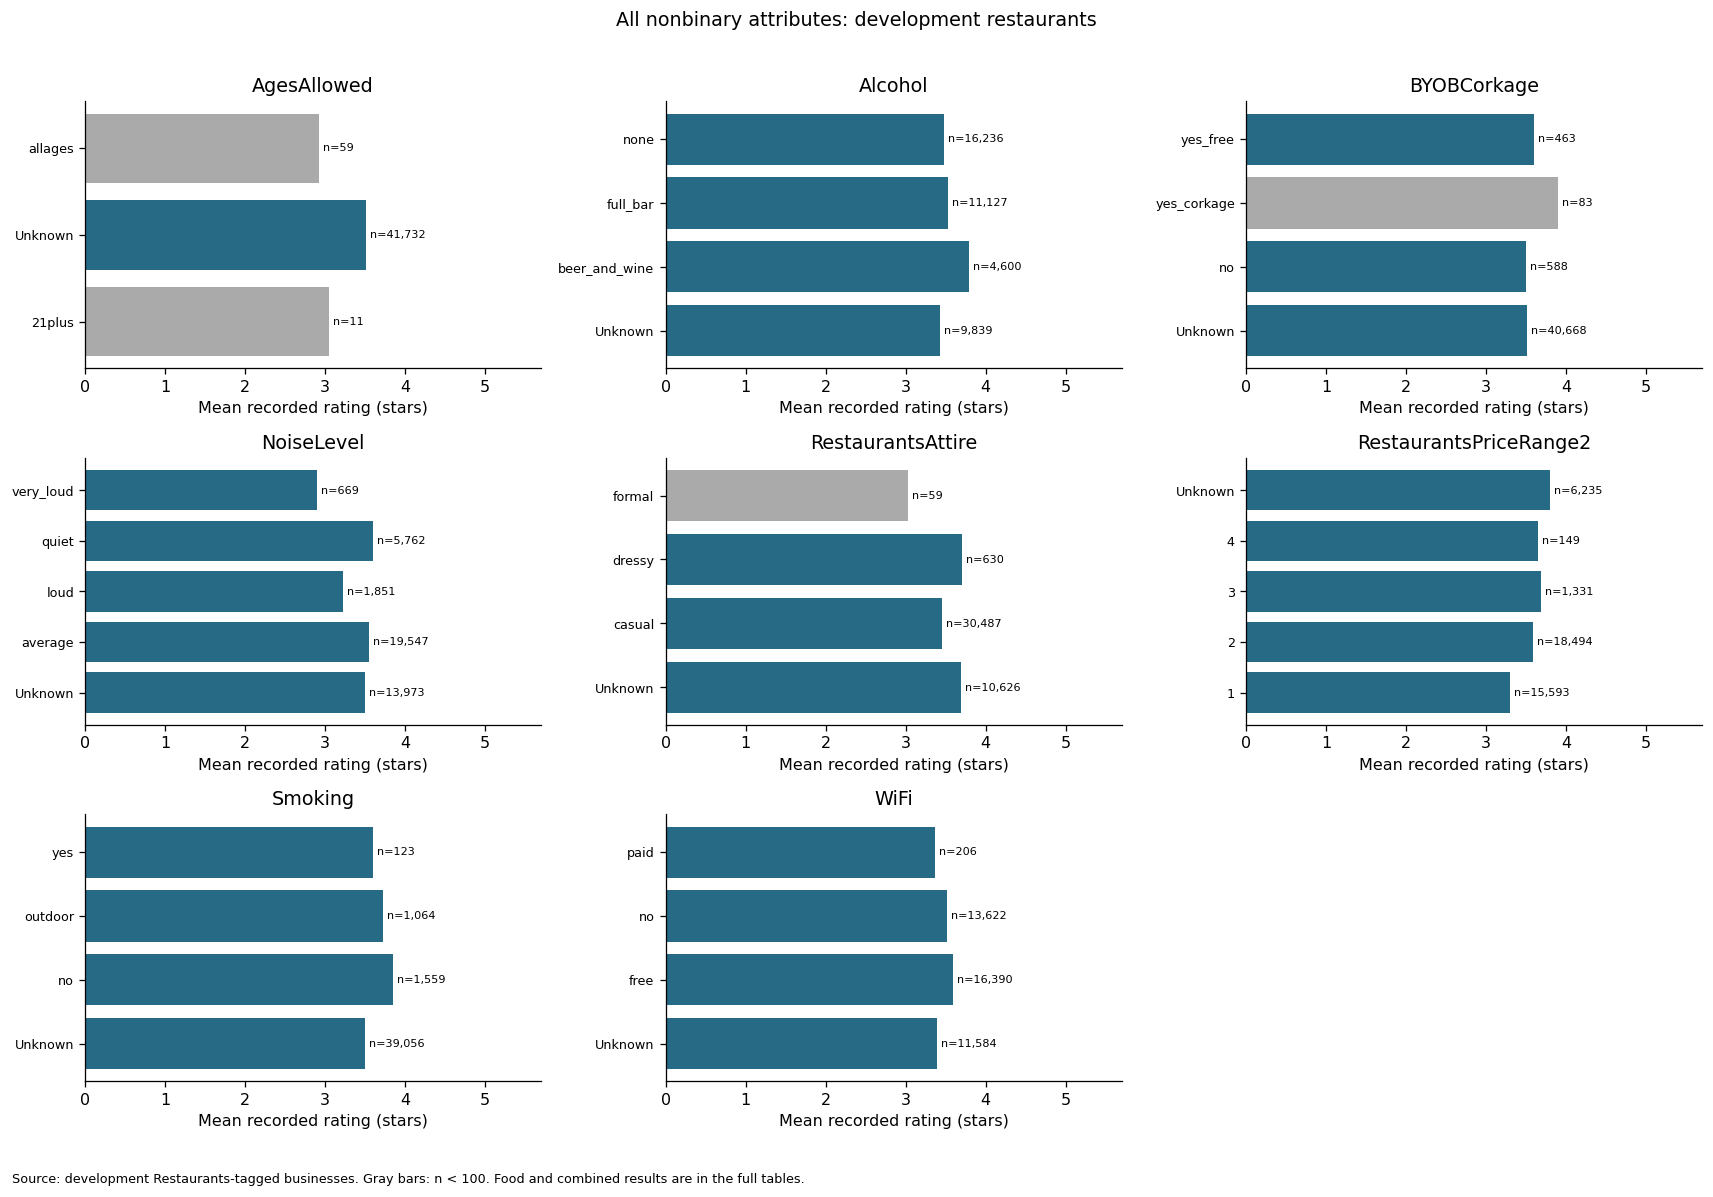

In [15]:
with _capture_output() as _captured_section:
    nonbinary_features = [c for c in attribute_frame if c not in binary_features]
    assert set(binary_features) | set(nonbinary_features) == set(attribute_frame.columns)
    columns = 3
    rows = int(np.ceil(len(nonbinary_features) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3.5 * rows), squeeze=False)
    for ax, feature in zip(axes.ravel(), nonbinary_features):
        data = attribute_levels.loc[attribute_levels.feature.eq(feature) & attribute_levels.scope.eq('Restaurants')].copy()
        data = data.sort_values('level')
        ax.barh(data.level, data.mean_stars, color=[BLUE if n >= 100 else '#AAAAAA' for n in data.n])
        for i, record in enumerate(data.itertuples()):
            ax.text(record.mean_stars + .05, i, f'n={record.n:,}', va='center', fontsize=7)
        ax.set(title=feature, xlim=(0, 5.7), xlabel='Mean recorded rating (stars)')
        ax.tick_params(axis='y', labelsize=8)
    for ax in axes.ravel()[len(nonbinary_features):]:
        ax.set_visible(False)
    fig.suptitle('All nonbinary attributes: development restaurants', fontsize=12)
    fig.tight_layout(rect=[0, .04, 1, .97])
    fig.text(.01, .01, 'Source: development Restaurants-tagged businesses. Gray bars: n < 100. Food and combined results are in the full tables.', fontsize=8)
    fig.savefig(OUT / '13_all_nonbinary_attribute_ratings.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Nonbinary attributes explored:', ', '.join(nonbinary_features))

_compact_result(_captured_section, 'All nonbinary attribute comparisons', '8c. Compare price, alcohol, Wi-Fi, noise, and other categories\n\nCompare every nonbinary attribute, keeping Unknown separate. Small groups are shown in gray with their counts.', [], ['Price, alcohol, Wi-Fi, noise, attire, and other levels'])

scope,category,n,mean_stars,median_stars,sd_stars,without_tag_n,without_tag_mean_stars,mean_difference_tag_vs_without,pct_of_population,supported_100_each
Restaurants,Acai Bowls,141,4.082,4.000,0.566,41661,3.513,0.569,0.337,True
Restaurants,Accessories,6,4.000,4.000,0.548,41796,3.514,0.486,0.014,False
Restaurants,Accountants,1,4.000,4.000,NaN,41801,3.515,0.485,0.002,False
Restaurants,Active Life,256,3.537,3.500,0.716,41546,3.514,0.023,0.612,True
Restaurants,Acupuncture,2,3.500,3.500,0.707,41800,3.515,-0.015,0.005,False
Restaurants,Adult,4,4.000,4.000,0.816,41798,3.514,0.486,0.010,False
Restaurants,Adult Education,2,4.500,4.500,0.707,41800,3.514,0.986,0.005,False
Restaurants,Adult Entertainment,24,3.208,3.000,0.721,41778,3.515,-0.306,0.057,False
Restaurants,Advertising,2,3.250,3.250,0.354,41800,3.515,-0.265,0.005,False
Restaurants,Afghan,35,4.171,4.000,0.593,41767,3.514,0.657,0.084,False

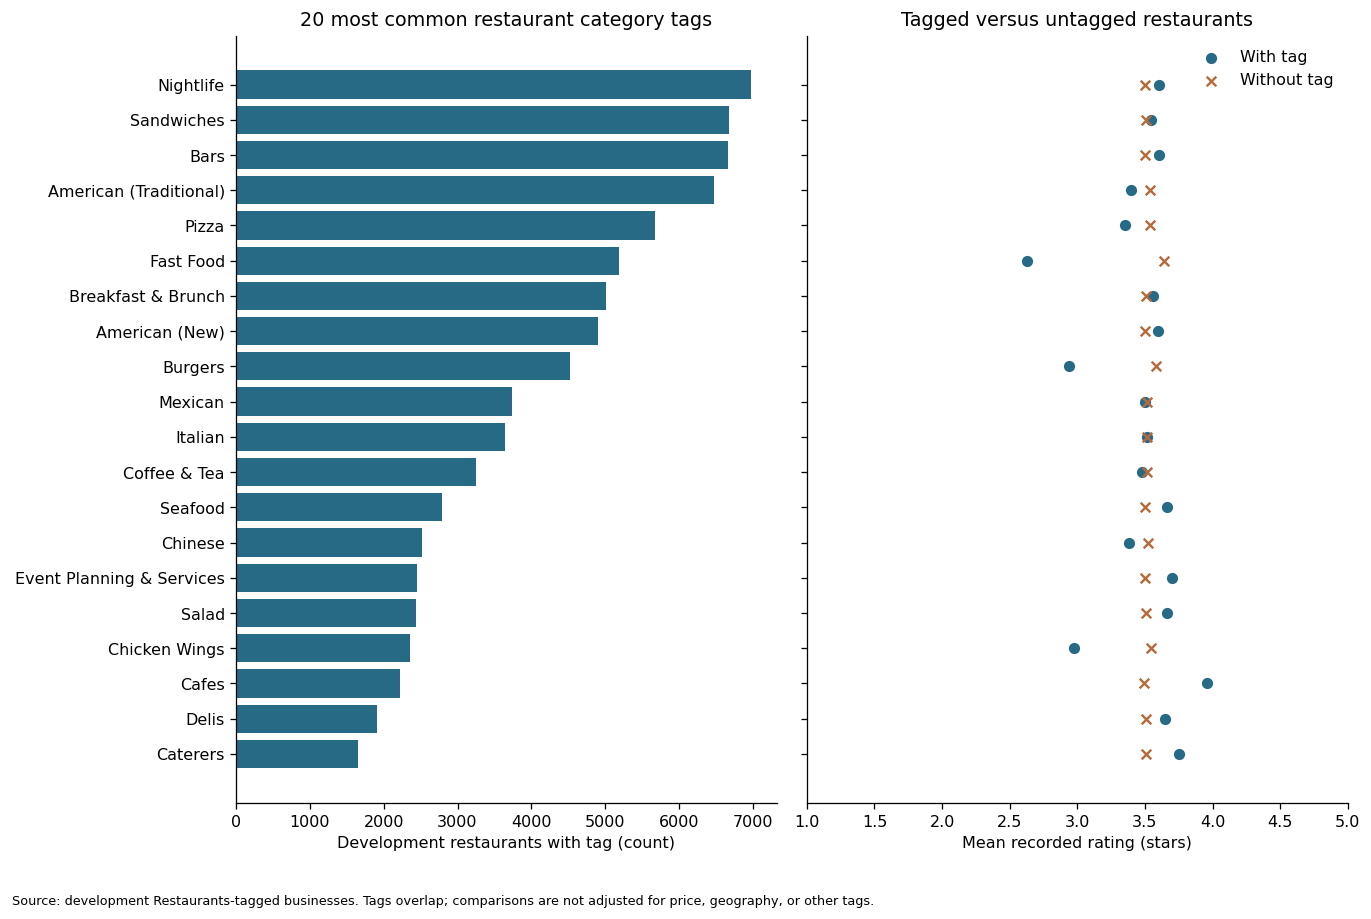

In [16]:
with _capture_output() as _captured_section:
    # All observed source tags are audited, including tags with zero development support.
    all_category_tags = sorted({tag for tags in category_lists.loc[comparison_businesses.index] for tag in tags})
    unique_category_lists = category_lists.loc[combined_dev.index].map(lambda tags: list(dict.fromkeys(tags)))
    unique_category_count = unique_category_lists.map(len)
    duplicate_category_entries = category_lists.loc[combined_dev.index].map(len) - unique_category_count
    print(f'{duplicate_category_entries.gt(0).sum():,} development businesses have repeated category tags; count each tag once per business.')
    category_long = unique_category_lists.explode().rename('category').to_frame()
    category_long['stars'] = combined_dev.stars
    category_long['business_id'] = combined_dev.business_id
    assert not category_long.reset_index().duplicated(['business_id', 'category']).any()
    category_tables, category_distribution_tables = [], []
    for scope, mask in scope_masks.items():
        scoped = combined_dev.loc[mask]
        long = category_long.loc[category_long.index.isin(scoped.index)]
        stats = long.groupby('category').stars.agg(n='size', mean_stars='mean', median_stars='median',
            sd_stars='std', sum_stars='sum').reindex(all_category_tags)
        stats['n'] = stats.n.fillna(0).astype(int)
        stats['sum_stars'] = stats.sum_stars.fillna(0)
        stats['without_tag_n'] = len(scoped) - stats.n
        stats['without_tag_mean_stars'] = (scoped.stars.sum() - stats.sum_stars) / stats.without_tag_n.replace(0, np.nan)
        stats['mean_difference_tag_vs_without'] = stats.mean_stars - stats.without_tag_mean_stars
        stats['pct_of_population'] = stats.n / len(scoped) * 100
        stats['supported_100_each'] = stats.n.ge(100) & stats.without_tag_n.ge(100)
        stats = stats.drop(columns='sum_stars').reset_index()
        stats.insert(0, 'scope', scope)
        category_tables.append(stats)
        distribution = pd.crosstab(long.category, long.stars).reindex(index=all_category_tags,
            columns=np.arange(1, 5.01, .5), fill_value=0)
        distribution = distribution.div(distribution.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
        distribution.columns = [f'pct_{rating:g}_stars' for rating in distribution.columns]
        distribution = distribution.reset_index()
        distribution.insert(0, 'scope', scope)
        category_distribution_tables.append(distribution)
    category_audit = pd.concat(category_tables, ignore_index=True)
    category_distributions = pd.concat(category_distribution_tables, ignore_index=True)
    assert set(category_audit.category) == set(all_category_tags)
    expandable_table('Every cuisine/business tag: support, ratings, and comparison with untagged businesses',
                     category_audit, 'all_category_tag_ratings.csv')
    expandable_table('Full rating distributions for every category tag',
                     category_distributions, 'all_category_tag_distributions.csv')
    common = category_audit.loc[category_audit.scope.eq('Restaurants') &
        ~category_audit.category.isin(['Restaurants', 'Food'])].sort_values('n', ascending=False).head(20).iloc[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
    axes[0].barh(common.category, common.n, color=BLUE)
    axes[0].set(xlabel='Development restaurants with tag (count)', title='20 most common restaurant category tags')
    axes[1].scatter(common.mean_stars, common.category, color=BLUE, label='With tag')
    axes[1].scatter(common.without_tag_mean_stars, common.category, color=ORANGE, marker='x', label='Without tag')
    axes[1].set(xlabel='Mean recorded rating (stars)', title='Tagged versus untagged restaurants', xlim=(1,5))
    axes[1].legend(frameon=False)
    fig.text(.01, .01, 'Source: development Restaurants-tagged businesses. Tags overlap; comparisons are not adjusted for price, geography, or other tags.', fontsize=8)
    fig.tight_layout(rect=[0, .05, 1, 1])
    fig.savefig(OUT / '14_all_category_tags.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'All {len(all_category_tags):,} category tags have coverage and rating summaries in the tables.')
    takeaway('Cuisine and business type supply information that category count alone cannot express. '
             'Differences across tags may also reflect location, price, and other overlapping tags.')

_compact_result(_captured_section, 'Cuisine and business categories', '8d. Explore cuisine and business categories\n\nCheck every category tag, not just the category count. Tags overlap; repeated tags within a business count once. Compare tagged and untagged businesses within each population; common restaurant tags are shown below.', [], ['Common categories and rating comparisons'])

feature,scope,known_n,missing_pct,min,p25,median,p75,max,spearman_with_stars,clock_time_no_linear_correlation
Monday_opening_clock_hour,Restaurants,23602,43.539,0.000,9.000,11.000,11.000,23.500,NaN,True
Monday_opening_clock_hour,Food,11752,47.032,0.000,7.000,9.000,11.000,23.500,NaN,True
Monday_opening_clock_hour,Food only,5084,48.297,0.000,7.000,8.000,10.000,23.500,NaN,True
Monday_opening_clock_hour,Combined,28686,44.445,0.000,8.000,10.500,11.000,23.500,NaN,True
Monday_closing_clock_hour,Restaurants,23602,43.539,0.000,17.000,21.000,22.000,23.983,NaN,True
Monday_closing_clock_hour,Food,11752,47.032,0.000,17.500,20.500,22.000,23.750,NaN,True
Monday_closing_clock_hour,Food only,5084,48.297,0.000,18.000,21.000,22.000,23.500,NaN,True
Monday_closing_clock_hour,Combined,28686,44.445,0.000,17.000,21.000,22.000,23.983,NaN,True
Monday_listed_hours,Restaurants,23602,43.539,0.250,9.000,11.000,12.500,23.983,-0.378,False
Monday_listed_hours,Food,11752,47.032,0.250,9.000,11.000,14.000,23.983,-0.452,False

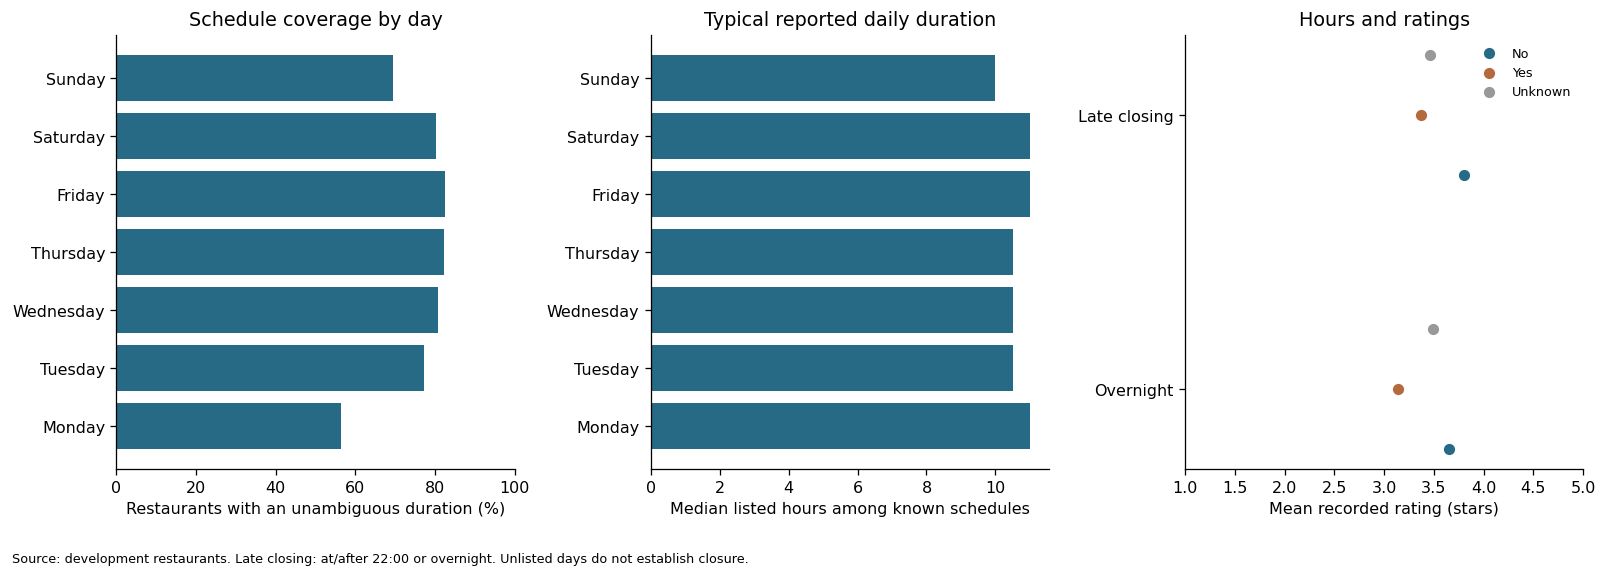

In [17]:
with _capture_output() as _captured_section:
    DAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    def detailed_schedule(hours):
        result = {}
        durations, overnight_flags, late_flags = {}, {}, {}
        for day in DAYS:
            start_hour = end_hour = duration = overnight = np.nan
            if isinstance(hours, dict) and day in hours:
                try:
                    start, end = hours[day].split('-')
                    start_min, end_min = time_minutes(start), time_minutes(end)
                    length = (end_min - start_min) % 1440
                    if length > 0:
                        start_hour, end_hour, duration = start_min / 60, end_min / 60, length / 60
                        overnight = float(end_min < start_min)
                except (ValueError, TypeError, AttributeError):
                    pass
            result[f'{day}_opening_clock_hour'] = start_hour
            result[f'{day}_closing_clock_hour'] = end_hour
            result[f'{day}_listed_hours'] = duration
            result[f'{day}_overnight'] = overnight
            durations[day] = duration
            overnight_flags[day] = overnight
            late_flags[day] = float(end_hour >= 22 or overnight == 1) if pd.notna(duration) else np.nan
        for label, days in [('weekday', DAYS[:5]), ('weekend', DAYS[5:])]:
            listed = [day for day in days if isinstance(hours, dict) and day in hours]
            result[f'{label}_listed_days'] = len(listed) if isinstance(hours, dict) and hours else np.nan
            result[f'{label}_listed_hours'] = sum(durations[d] for d in listed) if listed and all(
                pd.notna(durations[d]) for d in listed) else np.nan
        for label, flags in [('any_listed_overnight', overnight_flags), ('any_listed_late_closing', late_flags)]:
            listed = [d for d in DAYS if isinstance(hours, dict) and d in hours]
            result[label] = 1. if any(flags[d] == 1 for d in listed) else (
                0. if listed and all(pd.notna(flags[d]) for d in listed) else np.nan)
        return pd.Series(result)

    # Small semantic checks: overnight intervals, absent days, and equal-time ambiguity.
    check = detailed_schedule({'Friday': '18:00-2:00'})
    assert check.Friday_listed_hours == 8 and check.Friday_overnight == 1
    assert pd.isna(check.Saturday_listed_hours) and pd.isna(check.weekend_listed_hours)
    assert pd.isna(detailed_schedule({'Monday':'0:0-0:0'}).Monday_listed_hours)
    schedule_frame = raw_development.hours.apply(detailed_schedule)
    duration_columns = [c for c in schedule_frame if c.endswith('_listed_hours')]
    assert schedule_frame[duration_columns].stack().between(0,168).all()
    hours_summary_rows, hours_rating_tables = [], []
    for feature in schedule_frame:
        clock_time = '_clock_hour' in feature
        for scope, mask in scope_masks.items():
            values = schedule_frame.loc[mask, feature]
            target = combined_dev.loc[mask, 'stars']
            present = values.dropna()
            correlation = values.corr(target, method='spearman') if not clock_time and present.nunique() > 1 else np.nan
            hours_summary_rows.append({'feature': feature, 'scope': scope, 'known_n': len(present),
                'missing_pct': values.isna().mean() * 100, 'min': present.min(), 'p25': present.quantile(.25),
                'median': present.median(), 'p75': present.quantile(.75), 'max': present.max(),
                'spearman_with_stars': correlation, 'clock_time_no_linear_correlation': clock_time})
            if clock_time:
                bins = pd.cut(values, [-.001, 6, 12, 18, 24], right=False,
                              labels=['00:00–05:59', '06:00–11:59', '12:00–17:59', '18:00–23:59'])
                # Explicit 24:00 belongs to the midnight clock bin, without changing duration calculations.
                bins = bins.astype(object)
                bins.loc[values.eq(24)] = '00:00–05:59'
            elif present.nunique() <= 8:
                bins = values.map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
            else:
                bins = pd.cut(values, 4, include_lowest=True).astype(object)
            bin_labels = bins.map(lambda v: str(v) if pd.notna(v) else 'Unknown')
            stats = pd.DataFrame({'bin':bin_labels, 'stars':target}).groupby('bin').stars.agg(
                n='size', mean_stars='mean', median_stars='median', sd_stars='std').reset_index()
            stats.insert(0,'scope',scope)
            stats.insert(0,'feature',feature)
            hours_rating_tables.append(stats)
    hours_summary = pd.DataFrame(hours_summary_rows)
    hours_rating_comparisons = pd.concat(hours_rating_tables,ignore_index=True)
    assert set(hours_summary.feature) == set(schedule_frame.columns)
    expandable_table('Every detailed schedule feature: distribution, missingness, and correlations',
                     hours_summary, 'all_hours_summary.csv')
    expandable_table('Rating comparisons for every schedule feature, including Unknown',
                     hours_rating_comparisons, 'all_hours_rating_comparisons.csv')

    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    restaurant_schedule = schedule_frame.loc[scope_masks['Restaurants']]
    known_pct = [restaurant_schedule[f'{d}_listed_hours'].notna().mean()*100 for d in DAYS]
    median_hours = [restaurant_schedule[f'{d}_listed_hours'].median() for d in DAYS]
    axes[0].barh(DAYS, known_pct, color=BLUE)
    axes[0].set(xlabel='Restaurants with an unambiguous duration (%)', title='Schedule coverage by day', xlim=(0,100))
    axes[1].barh(DAYS, median_hours, color=BLUE)
    axes[1].set(xlabel='Median listed hours among known schedules', title='Typical reported daily duration')
    for j, feature in enumerate(['any_listed_overnight','any_listed_late_closing']):
        rows = hours_rating_comparisons.loc[hours_rating_comparisons.feature.eq(feature) &
                                          hours_rating_comparisons.scope.eq('Restaurants')].set_index('bin')
        for offset, label, color in [(-.22,'0',BLUE),(0,'1',ORANGE),(.22,'Unknown','#999999')]:
            if label in rows.index:
                axes[2].scatter(rows.loc[label,'mean_stars'],j+offset,color=color,
                    label={'0':'No','1':'Yes','Unknown':'Unknown'}[label] if j==0 else None)
    axes[2].set(yticks=[0,1],yticklabels=['Overnight','Late closing'],xlabel='Mean recorded rating (stars)',
                title='Hours and ratings',xlim=(1,5))
    axes[2].legend(frameon=False,fontsize=8)
    fig.text(.01,.01,'Source: development restaurants. Late closing: at/after 22:00 or overnight. Unlisted days do not establish closure.',fontsize=8)
    fig.tight_layout(rect=[0,.06,1,1])
    fig.savefig(OUT/'15_detailed_hours.png',dpi=150,bbox_inches='tight')
    plt.show()
    takeaway('Daily schedules and weekend hours are potential planning inputs, but missing schedules remain unknown. '
             'These recorded hours may have changed after opening, so their associations do not validate an opening-day forecast.')

_compact_result(_captured_section, 'Daily opening hours', "8e. Explore detailed opening hours\n\nCheck each day's opening time, closing time, duration, and overnight status, plus weekday/weekend totals. Unlisted days stay unknown. Clock times wrap at midnight, so simple correlations are omitted for them.", [], ['Daily coverage, durations, and late hours'])

In [18]:
with _capture_output() as _captured_section:
    raw_field_roles = {
        'business_id':'Identifier; exclude as predictor', 'name':'Possible chain feature; not a direct predictor',
        'address':'Possible neighborhood feature; not a direct predictor', 'city':'Location candidate',
        'state':'Location candidate', 'postal_code':'Location candidate; sparse levels need pooling',
        'latitude':'Location candidate', 'longitude':'Location candidate', 'stars':'Target; never a predictor',
        'review_count':'After customer activity; descriptive only for pre-opening question',
        'is_open':'Snapshot operating/closure status; exclude for pre-opening question',
        'attributes':'All available keys and nested options audited above',
        'categories':'All tags audited above; platform labeling may develop after opening',
        'hours':'All listed daily schedules audited above; historical timing unverified',
    }
    assert set(raw_field_roles)==set(business.columns)
    raw_audit=[]
    for field,role in raw_field_roles.items():
        values=raw_development[field]
        distinct=values.map(str).nunique() if field in ['attributes','hours'] else values.nunique()
        raw_audit.append({'raw_field':field,'role':role,'missing_pct':values.isna().mean()*100,
                          'distinct_development_values':int(distinct)})
    expandable_table('All raw business fields and their intended roles',pd.DataFrame(raw_audit),'raw_field_inventory.csv')

    # Full location-level summaries supplement the original geography plots.
    location_tables=[]
    for feature in ['state','city_state','postal_code']:
        for scope,mask in scope_masks.items():
            subset=combined_dev.loc[mask]
            grouped=subset.assign(level=subset[feature].fillna('Unknown').astype(str)).groupby('level').stars.agg(
                n='size',mean_stars='mean',median_stars='median',sd_stars='std').reset_index()
            grouped.insert(0,'scope',scope);grouped.insert(0,'feature',feature)
            grouped['small_group_under_100']=grouped.n.lt(100)
            location_tables.append(grouped)
    location_summary=pd.concat(location_tables,ignore_index=True)
    expandable_table('Every state, city-state, and postal code: counts and ratings',location_summary,
                     'all_location_level_ratings.csv')

    # Audit unique category counts separately; preserve the original model's input files.
    category_count_quality = pd.DataFrame({'raw_category_count':combined_dev.category_count,
        'unique_category_count':unique_category_count,'duplicate_category_entries':duplicate_category_entries,
        'stars':combined_dev.stars})
    count_checks=[]
    for field in ['raw_category_count','unique_category_count','duplicate_category_entries']:
        grouped=category_count_quality.groupby(field).stars.agg(n='size',mean_stars='mean',median_stars='median').reset_index()
        grouped=grouped.rename(columns={field:'value'});grouped.insert(0,'feature',field)
        count_checks.append(grouped)
    expandable_table('Raw versus unique category counts and repeated entries',
        pd.concat(count_checks,ignore_index=True),'category_count_quality.csv')

    # Missingness can be predictive but may describe customer reporting or platform activity.
    missingness_rows=[]
    for feature in attribute_frame:
        values=attribute_frame[feature]
        target=combined_dev.stars
        missing=values.isna()
        missingness_rows.append({'feature':feature,'missing_n':int(missing.sum()),
            'reported_n':int((~missing).sum()),'mean_stars_missing':target.loc[missing].mean(),
            'mean_stars_reported':target.loc[~missing].mean(),
            'mean_difference_missing_minus_reported':target.loc[missing].mean()-target.loc[~missing].mean()})
    expandable_table('Missing versus reported attributes: combined development businesses',
                     pd.DataFrame(missingness_rows),'missingness_rating_associations.csv')

    # Existing engineered quality flags, group indicators, and operating status are audited explicitly.
    flag_tables=[]
    for feature in ['hours_ambiguous','hours_malformed','is_restaurant_tag','is_food_tag','category_group','is_open']:
        for scope,mask in scope_masks.items():
            subset=combined_dev.loc[mask]
            grouped=subset.assign(level=subset[feature].fillna('Unknown').astype(str)).groupby('level').stars.agg(
                n='size',mean_stars='mean',median_stars='median').reset_index()
            grouped.insert(0,'scope',scope);grouped.insert(0,'feature',feature)
            flag_tables.append(grouped)
    expandable_table('Group flags, schedule-quality flags, and operating status (descriptive)',
                     pd.concat(flag_tables,ignore_index=True),'engineered_flag_ratings.csv')

    audit_summary={'development_businesses':len(combined_dev),'source_attributes':len(all_keys),
        'extracted_attribute_options':len(attribute_frame.columns),'binary_options':len(binary_features),
        'nonbinary_options':len(nonbinary_features),'category_tags':len(all_category_tags),
        'businesses_with_repeated_category_tags':int(duplicate_category_entries.gt(0).sum()),
        'detailed_schedule_features':len(schedule_frame.columns),'raw_fields':len(raw_field_roles),
        'sparse_attribute_options_under_100_known':int(attribute_inventory.sparse_under_100_known.sum()),
        'analysis_uses_development_only':True,'models_retrained':False,
        'scope':'Pre-opening planning candidates and descriptive exclusions; snapshot values are not verified pre-opening records'}
    (AUDIT/'summary.json').write_text(json.dumps(audit_summary,indent=2,allow_nan=False))
    (AUDIT/'feature_roles.json').write_text(json.dumps({c:planning_role(attribute_roots[c]) for c in attribute_frame},indent=2))
    print('Completed full predictor audit:',audit_summary)
    takeaway('The EDA now covers every available business attribute and category tag, plus detailed hours and location levels. '
             'Coverage and associations identify candidates to test; they do not prove that changing a feature will raise ratings.')

_compact_result(_captured_section, 'Remaining fields and full audit', '8f. Check remaining fields and summarize coverage\n\nAudit location, identifiers, review counts, and missingness flags. Names and addresses need feature engineering; customer activity and closure status do not fit a pre-opening model. New tables are exploratory and do not change notebook 02.', [], [])

raw_field,role,missing_pct,distinct_development_values
business_id,Identifier; exclude as predictor,0.000,51635
name,Possible chain feature; not a direct predictor,0.000,35742
address,Possible neighborhood feature; not a direct predictor,0.000,42727
city,Location candidate,0.000,927
state,Location candidate,0.000,19
postal_code,Location candidate; sparse levels need pooling,0.000,2104
latitude,Location candidate,0.000,48760
longitude,Location candidate,0.000,48267
stars,Target; never a predictor,0.000,9
review_count,After customer activity; descriptive only for pre-opening question,0.000,1071


In [19]:
with _capture_output() as _captured_section:
    feature_spec = {'target': 'stars', 'id': 'business_id', 'split': 'split',
                    'numeric_candidates': numeric_features, 'categorical_candidates': categorical_features,
                    'excluded_from_core': ['review_count', 'log1p_review_count', 'is_open', 'postal_code', 'city',
                                           'hours_ambiguous', 'hours_malformed']}
    for split in ['development', 'holdout']:
        frame = feature_frame.loc[feature_frame.split.eq(split)].copy()
        frame.to_csv(PROCESSED / f'restaurants_{split}.csv', index=False)
    restaurants[['business_id', 'split']].to_csv(PROCESSED / 'restaurant_split.csv', index=False)
    (OUT / 'feature_spec.json').write_text(json.dumps(feature_spec, indent=2))
    missingness.to_csv(OUT / 'missingness.csv', index_label='variable')
    price_summary.to_csv(OUT / 'rating_by_price.csv', index_label='price_range')
    amenity_summary.to_csv(OUT / 'amenity_summary.csv', index=False)
    delivery_city_summary.to_csv(OUT / 'delivery_by_city.csv', index=False)
    correlations.to_csv(OUT / 'spearman_correlations.csv')
    print('Saved development and holdout CSVs, split assignments, and summary files.')
    print('Raw data unchanged. No predictive models fitted and no holdout performance calculated.')

    # Separate candidate inputs; preserve the restaurant files used by notebook 02.
    for population, selection in {
        'food': combined_features.is_food_tag,
        'restaurants_or_food': pd.Series(True, index=combined_features.index),
    }.items():
        for partition in ['development', 'holdout']:
            candidate = combined_features.loc[selection & combined_features['split'].eq(partition)].copy()
            assert candidate.business_id.is_unique
            candidate.to_csv(PROCESSED / f'{population}_{partition}.csv', index=False)
    combined_features[['business_id', 'split', 'is_restaurant_tag', 'is_food_tag', 'category_group']].to_csv(
        PROCESSED / 'restaurants_or_food_split.csv', index=False)
    print('Also saved Food-tagged and Restaurants-or-Food candidate files; Food includes businesses with both tags.')


_compact_result(_captured_section, 'Saved modeling datasets', '9. Save the prepared data\n\nSave separate development and holdout files for Restaurants, Food, and their union. Predict stars from business attributes; keep business_id for tracking only.', [], [])

In [20]:
with _capture_output() as _captured_section:
    summary = {
        'question': 'Predict recorded restaurant-average stars from business attributes in the observed snapshot.',
        'source': 'Yelp Open Dataset downloaded 2026-10-21; business file only for this EDA.',
        'all_businesses': int(len(business)), 'all_restaurants': int(len(restaurants)),
        'development_restaurants': int(len(dev)), 'holdout_restaurants': int(len(holdout_ids)),
        'zero_us_states': zero_states,
        'sparse_regions': {str(k): int(v) for k, v in all_state_counts[all_state_counts < 30].items()},
        'all_state_counts': {str(k): int(v) for k, v in all_state_counts.items()},
        'mean_stars': float(dev.stars.mean()), 'median_stars': float(dev.stars.median()),
        'median_review_count': float(dev.review_count.median()), 'share_under_20_reviews': low_count_fraction,
        'ambiguous_hours_n': int(dev.hours_ambiguous.sum()),
        'city_label_changes': city_label_changes,
        'rating_distribution': [{'stars': float(k), 'restaurants': int(v)} for k, v in rating_counts.items()],
        'missingness': [{'field': str(k), 'pct': float(v)} for k, v in missingness.missing_pct.items()],
        'price_summary': [{'price': str(k), 'n': int(v['size']), 'mean': float(v['mean'])} for k, v in price_summary.iterrows()],
        'amenities': amenity_rows,
        'delivery_cities': delivery_city_summary.to_dict(orient='records'),
        'markets': {},
    }
    for market in ['All development', *state_counts[state_counts >= 100].index.tolist()]:
        subset = dev if market == 'All development' else dev.loc[dev.state.eq(market)]
        counts = subset.stars.value_counts().reindex(np.arange(1, 5.01, .5), fill_value=0).sort_index()
        summary['markets'][market] = {'n': int(len(subset)), 'mean': float(subset.stars.mean()),
            'ratings': [int(x) for x in counts.values],
            'price': [{'label': str(k), 'n': int(v['size']), 'mean': float(v['mean'])}
                      for k, v in subset.assign(price_group=subset.price_range.fillna('Unknown')).groupby('price_group').stars.agg(['size', 'mean']).iterrows()]}
    (OUT / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False))
    takeaway(f'We identified {len(restaurants):,} restaurants and reserved {len(holdout_ids):,} for later evaluation. '
             f'On {len(dev):,} development restaurants, the mean recorded rating is {dev.stars.mean():.2f} stars; '
             f'{low_count_fraction:.1%} have fewer than 20 reviews. '
             f'Coverage is geographically restricted: {len(zero_states)} US states have no restaurant rows, so these findings do not represent the nation.')

_compact_result(_captured_section, 'EDA summary', '10. Review the findings\n\nSummarize what the data suggests for modeling.\n\nAll available attributes and category tags are now summarized, including sparse and perception-based fields. Missingness and snapshot timing affect whether they are suitable for pre-opening planning.\n\nNotebook 02 still contains the original restaurant model results. Its holdout has already been evaluated; expanded features and Food/combined models remain untested.\n\nData sources and AI assistance are documented in data/source_manifest.json and AI_USAGE.md.', [], [])